# Note 09 — Final Synthesis

## 1. Research Question

Các kết quả từ Note 01–08 liên kết với nhau như thế nào để giải thích mối quan hệ giữa electricity transition và carbon outcome, đồng thời Vietnam đã đi theo pathway nào trong bối cảnh chuyển dịch toàn cầu?

## 2. Objective

- Tổng hợp các evidence quan trọng từ Note 01–08.
- Liên kết Global Transition, Structural Shift và Carbon Outcome thành một storyline thống nhất.
- Đối chiếu các transition patterns và decoupling outcomes đã phát hiện.
- Sử dụng Vietnam như một case study để minh họa turning point và source replacement.
- Hình thành kết luận cuối cùng cho Research Question của toàn bộ project.

## 3. Approach

Không thực hiện một nhánh phân tích mới. Note 09 tổng hợp và kết nối các kết quả đã được kiểm định từ Note 01–08 thông qua các visualization và comparative evidence quan trọng.

## 4. Expected Outcome

Hình thành một evidence chain thống nhất:

**Global Transition → Structural Shift → Carbon Outcome → Decoupling → Strong vs Bad → International Spotlight → Vietnam Turning Point → Source Replacement → Conclusion**

## 5. Final Research Question

**How does the transition in electricity generation mix relate to changes in carbon emissions across countries?**

Vietnam được sử dụng như một case study để kiểm tra cụ thể pathway chuyển dịch, đặc biệt trong giai đoạn turning point 2021–2022.

In [1]:
# ============================================================
# NOTE 09 — FINAL SYNTHESIS
#
# Summary: Sự chuyển đổi trong cơ cấu sản xuất điện có liên quan như thế nào đến 
# sự thay đổi lượng khí thải carbon giữa các quốc gia?
# ============================================================

from pathlib import Path
import pickle
import pandas as pd

project_root = Path.cwd().parent
checkpoint_dir = project_root / "checkpoints"

print("Project root:", project_root)
print("Checkpoint directory:", checkpoint_dir)

# ------------------------------------------------------------
# 1. Các checkpoint cần dùng cho Note 9
# ------------------------------------------------------------
checkpoint_files = {
    "note03": checkpoint_dir / "note03_eda_overview.pkl",
    "note06": checkpoint_dir / "note06_country_transition_profiles.pkl",
    "note07": checkpoint_dir / "note07_relationship_deeper_analysis.pkl",
    "note08": checkpoint_dir / "note08_carbon_transition_rq4.pkl",
}

print("\nKiểm tra checkpoint:")
for name, path in checkpoint_files.items():
    print(f"- {name}: {'OK' if path.exists() else 'MISSING'}")
    
if not all(path.exists() for path in checkpoint_files.values()):
    missing = [name for name, path in checkpoint_files.items() if not path.exists()]
    raise FileNotFoundError(
        f"Thiếu checkpoint: {missing}. "
        "Kiểm tra lại thư mục checkpoints trước khi tiếp tục."
    )

# ------------------------------------------------------------
# 2. Load checkpoint
# ------------------------------------------------------------
loaded = {}

for name, path in checkpoint_files.items():
    with open(path, "rb") as f:
        loaded[name] = pickle.load(f)

print("\nĐã load:")
for name, obj in loaded.items():
    if isinstance(obj, dict):
        print(f"- {name}: dictionary với {len(obj)} objects")
    else:
        print(f"- {name}: {type(obj).__name__}")

# ------------------------------------------------------------
# 3. Tách các object quan trọng
# ------------------------------------------------------------

# Note 3: dataframe gốc + kết quả EDA
note03 = loaded["note03"]

# Note 6: country transition profiles
note06 = loaded["note06"]

# Note 7: relationship / deeper analysis
note07 = loaded["note07"]

# Note 8: carbon transition + decoupling + Vietnam-related results
note08 = loaded["note08"]

print("\nKiểm tra cấu trúc checkpoint:")

for name, obj in [
    ("Note 3", note03),
    ("Note 6", note06),
    ("Note 7", note07),
    ("Note 8", note08),
]:
    print(f"\n{name}:")
    if isinstance(obj, dict):
        print("  Objects:", list(obj.keys()))
    else:
        print(" ", type(obj).__name__)

Project root: d:\phan tich data\Ember_Electricity
Checkpoint directory: d:\phan tich data\Ember_Electricity\checkpoints

Kiểm tra checkpoint:
- note03: OK
- note06: OK
- note07: OK
- note08: OK

Đã load:
- note03: dictionary với 15 objects
- note06: dictionary với 13 objects
- note07: dictionary với 6 objects
- note08: dictionary với 11 objects

Kiểm tra cấu trúc checkpoint:

Note 3:
  Objects: ['df', 'generation_sources', 'system_sources', 'source_summary', 'global_trend', 'global_sources', 'country_core_coverage', 'country_panel', 'country_source_panel', 'wind_coverage', 'country_generation_2022', 'country_mix_2022', 'country_mix_check', 'mix_balance', 'nuclear_2022']

Note 6:
  Objects: ['country_transition', 'transition_features', 'transition_profile', 'profile', 'size_profile', 'transition_size_table', 'intensity_by_size', 'decline_profile', 'profile_compare', 'profile_size', 'profile_size_count', 'profile_size_pct', 'profile_size_generation']

Note 7:
  Objects: ['profile', 'decl

In [18]:
# ============================================================
# Evidence Chain — Note 1 → Note 8
#
# Mục đích:
# - Liên kết các kết quả đã hoàn thành từ Note 1 → Note 8.
# - Không thực hiện lại phân tích.
# - Xác định vai trò của từng Note trong storyline cuối.
# ============================================================

evidence_chain = pd.DataFrame([
    {
        "Note": "Note 1",
        "Analysis": "Initial Dataset & Data Understanding",
        "Key Question": "Dataset có cấu trúc và phạm vi như thế nào?",
        "Key Evidence": "104,203 rows × 24 columns; 1985–2025; 224 areas; 17 electricity sources.",
        "Role": "Xác định phạm vi và cấu trúc dữ liệu.",
        "Leads To": "Note 2 — kiểm tra chất lượng dữ liệu"
    },
    {
        "Note": "Note 2",
        "Analysis": "Data Quality & Structure",
        "Key Question": "Dữ liệu có đủ tin cậy để phân tích không?",
        "Key Evidence": "Kiểm tra missingness, duplicate, negative values và consistency giữa các nguồn điện.",
        "Role": "Xác nhận dữ liệu đủ điều kiện cho phân tích.",
        "Leads To": "Note 3 — phân tích xu hướng toàn cầu"
    },
    {
        "Note": "Note 3",
        "Analysis": "Global EDA",
        "Key Question": "Cơ cấu điện toàn cầu đã thay đổi như thế nào?",
        "Key Evidence": "Renewables tăng từ 18.71% (2000) lên 33.48% (2025); Fossil giảm từ 64.71% xuống 57.69%.",
        "Role": "Thiết lập bức tranh chuyển dịch năng lượng toàn cầu.",
        "Leads To": "Note 4–5 — tìm và xác thực các điểm chuyển dịch bất thường"
    },
    {
        "Note": "Note 4–5",
        "Analysis": "Anomaly & Event Validation",
        "Key Question": "Những thay đổi nổi bật xảy ra ở đâu và có thực sự là thay đổi nguồn điện không?",
        "Key Evidence": "Phát hiện các country-year có biến động bất thường; kiểm tra lại bằng Generation và Total generation.",
        "Role": "Xác định turning points và phân biệt biến động thực với hiệu ứng mẫu số.",
        "Leads To": "Note 6 — xây dựng hồ sơ chuyển dịch quốc gia"
    },
    {
        "Note": "Note 6",
        "Analysis": "Country Energy Transition Profiles",
        "Key Question": "Các quốc gia chuyển dịch theo những pathway nào?",
        "Key Evidence": "So sánh thay đổi Fossil, Renewables và các nguồn thành phần trong giai đoạn 2012–2022.",
        "Role": "Chuyển từ xu hướng toàn cầu sang khác biệt giữa các quốc gia.",
        "Leads To": "Note 7 — kiểm tra mối quan hệ giữa transition và carbon"
    },
    {
        "Note": "Note 7",
        "Analysis": "Relationship / Deeper Analysis",
        "Key Question": "Thay đổi cơ cấu nguồn điện liên hệ như thế nào với carbon outcome?",
        "Key Evidence": "Renewables/Fossil có quan hệ mạnh với carbon intensity; carbon intensity là outcome liên hệ rõ nhất với energy mix.",
        "Role": "Nối Energy Transition với Carbon Outcome.",
        "Leads To": "Note 8 — kiểm tra trực tiếp các trường hợp decoupling"
    },
    {
        "Note": "Note 8",
        "Analysis": "Carbon, Capacity & Decoupling",
        "Key Question": "Khi sản lượng điện tăng, điều gì phân biệt kết quả carbon tốt và xấu?",
        "Key Evidence": "Strong Decoupling gắn với Fossil share giảm mạnh và Renewables share tăng; Fossil và Renewables có effect size lớn nhất.",
        "Role": "Đóng RQ4: xác định pattern của transition đi kèm carbon outcome tốt.",
        "Leads To": "Note 9 — tổng hợp toàn bộ storyline"
    }
])

print("=== EVIDENCE CHAIN: NOTE 1 → NOTE 8 ===\n")
display(evidence_chain)

print("\n=== STORYLINE ===")
print(
    "DATA → GLOBAL TRANSITION → TURNING POINT → "
    "COUNTRY PATHWAY → CARBON OUTCOME → DECOUPLING → SYNTHESIS"
)

print("\n=== CENTRAL QUESTION ===")
print(
    "Sự chuyển dịch cơ cấu nguồn điện có thực sự đi kèm với quá trình giảm phát thải carbon ở các quốc gia hay không?"
)

=== EVIDENCE CHAIN: NOTE 1 → NOTE 8 ===



,Note,Analysis,Key Question,Key Evidence,Role,Leads To
0,Note 1,Initial Dataset & Data Understanding,Dataset có cấu trúc và phạm vi như thế nào?,"104,203 rows × 24 columns; 1985–2025; 224 area...",Xác định phạm vi và cấu trúc dữ liệu.,Note 2 — kiểm tra chất lượng dữ liệu
1,Note 2,Data Quality & Structure,Dữ liệu có đủ tin cậy để phân tích không?,"Kiểm tra missingness, duplicate, negative valu...",Xác nhận dữ liệu đủ điều kiện cho phân tích.,Note 3 — phân tích xu hướng toàn cầu
2,Note 3,Global EDA,Cơ cấu điện toàn cầu đã thay đổi như thế nào?,Renewables tăng từ 18.71% (2000) lên 33.48% (2...,Thiết lập bức tranh chuyển dịch năng lượng toà...,Note 4–5 — tìm và xác thực các điểm chuyển dịc...
3,Note 4–5,Anomaly & Event Validation,Những thay đổi nổi bật xảy ra ở đâu và có thực...,Phát hiện các country-year có biến động bất th...,Xác định turning points và phân biệt biến động...,Note 6 — xây dựng hồ sơ chuyển dịch quốc gia
4,Note 6,Country Energy Transition Profiles,Các quốc gia chuyển dịch theo những pathway nào?,"So sánh thay đổi Fossil, Renewables và các ngu...",Chuyển từ xu hướng toàn cầu sang khác biệt giữ...,Note 7 — kiểm tra mối quan hệ giữa transition ...
5,Note 7,Relationship / Deeper Analysis,Thay đổi cơ cấu nguồn điện liên hệ như thế nào...,Renewables/Fossil có quan hệ mạnh với carbon i...,Nối Energy Transition với Carbon Outcome.,Note 8 — kiểm tra trực tiếp các trường hợp dec...
6,Note 8,"Carbon, Capacity & Decoupling","Khi sản lượng điện tăng, điều gì phân biệt kết...",Strong Decoupling gắn với Fossil share giảm mạ...,Đóng RQ4: xác định pattern của transition đi k...,Note 9 — tổng hợp toàn bộ storyline



=== STORYLINE ===
DATA → GLOBAL TRANSITION → TURNING POINT → COUNTRY PATHWAY → CARBON OUTCOME → DECOUPLING → SYNTHESIS

=== CENTRAL QUESTION ===
Sự chuyển dịch cơ cấu nguồn điện có thực sự đi kèm với quá trình giảm phát thải carbon ở các quốc gia hay không?


In [3]:
# ============================================================
# - Xác định dataframe nào sẽ được tái sử dụng cho từng Figure.
# - Kiểm tra shape và các biến chính trước khi trực quan hóa.
# ============================================================

print("=== OBJECTS PHỤC VỤ NOTE 09 ===\n")

# ------------------------------------------------------------
# 1. Global story — Note 3
# ------------------------------------------------------------
df = note03["df"]
global_trend = note03["global_trend"]
global_sources = note03["global_sources"]

print("[1] GLOBAL")
print("df:", df.shape)
print("global_trend:", global_trend.shape)
print("global_sources:", global_sources.shape)

print("\nGlobal trend columns:")
print(global_trend.columns.tolist())

print("\nGlobal sources columns:")
print(global_sources.columns.tolist())


# ------------------------------------------------------------
# 2. Country transition — Note 6
# ------------------------------------------------------------
profile = note06["profile"]
transition_features = note06["transition_features"]

print("\n[2] COUNTRY TRANSITION")
print("profile:", profile.shape)
print("transition_features:", transition_features.shape)

print("\nProfile columns:")
print(profile.columns.tolist())

print("\nTransition features columns:")
print(transition_features.columns.tolist())


# ------------------------------------------------------------
# 3. Relationship — Note 7
# ------------------------------------------------------------
overall_results_df = note07["overall_results_df"]
final_relationship = note07["final_relationship"]

print("\n[3] RELATIONSHIP / CARBON")
print("overall_results_df:", overall_results_df.shape)
print("final_relationship:", final_relationship.shape)

print("\nOverall relationship columns:")
print(overall_results_df.columns.tolist())

print("\nFinal relationship:")
print(final_relationship)


# ------------------------------------------------------------
# 4. Decoupling — Note 8
# ------------------------------------------------------------
strong = note08["strong"]
strong_mix = note08["strong_mix"]
bad_mix = note08["bad_mix"]
stat_results = note08["stat_results"]

print("\n[4] DECOUPLING")
print("strong:", strong.shape)
print("strong_mix:", strong_mix.shape)
print("bad_mix:", bad_mix.shape)
print("stat_results:", stat_results.shape)

print("\nStrong columns:")
print(strong.columns.tolist())

print("\nStrong mix columns:")
print(strong_mix.columns.tolist())

print("\nBad mix columns:")
print(bad_mix.columns.tolist())

print("\nStatistical comparison columns:")
print(stat_results.columns.tolist())


# ------------------------------------------------------------
# 5. Tổng hợp vai trò của từng object
# ------------------------------------------------------------
visualization_sources = {
    "Global transition": "global_trend / global_sources",
    "Country transition": "profile / transition_features",
    "Transition–Carbon relationship": "overall_results_df / final_relationship",
    "Strong decoupling": "strong / strong_mix",
    "Bad decoupling": "bad_mix",
    "Strong vs Bad statistical comparison": "stat_results"
}

print("\n=== VISUALIZATION SOURCES ===")
for figure_group, source in visualization_sources.items():
    print(f"- {figure_group}: {source}")

print("→ Bước tiếp theo: Trực quan hóa Figure 1 — Global Electricity Transition.")

=== OBJECTS PHỤC VỤ NOTE 09 ===

[1] GLOBAL
df: (104203, 24)
global_trend: (78, 4)
global_sources: (130, 4)

Global trend columns:
['Year', 'Electricity source', 'Generation (TWh)', 'Share of generation (%)']

Global sources columns:
['Year', 'Electricity source', 'Generation (TWh)', 'Share of generation (%)']

[2] COUNTRY TRANSITION
profile: (209, 13)
transition_features: (209, 7)

Profile columns:
['Area', 'Delta_Fossil_share_pp', 'Delta_Renewables_share_pp', 'Delta_Solar_share_pp', 'Delta_Wind_share_pp', 'Delta_Hydro_share_pp', 'Delta_Nuclear_share_pp', 'Generation_2012_TWh', 'Generation_2022_TWh', 'Transition_direction', 'Transition_intensity_pp', 'Dominant_renewable_change', 'Solar_transition_strength']

Transition features columns:
['Area', 'Delta_Fossil_share_pp', 'Delta_Renewables_share_pp', 'Delta_Solar_share_pp', 'Delta_Wind_share_pp', 'Delta_Hydro_share_pp', 'Delta_Nuclear_share_pp']

[3] RELATIONSHIP / CARBON
overall_results_df: (7, 6)
final_relationship: (7, 8)

Overall re

=== FIGURE 1 — GLOBAL ELECTRICITY MIX ===
Giai đoạn: 2000 → 2025
Số năm: 26

Sai lệch lớn nhất so với 100%:
0.0000000000 percentage points

--- Cơ cấu năm 2000 ---


,Share (%)
Electricity source,
Coal,38.114
Gas,17.925
Hydro,17.178
Solar,0.007
Wind,0.203
Other sources,26.573



--- Cơ cấu năm 2025 ---


,Share (%)
Electricity source,
Coal,33.347
Gas,21.762
Hydro,13.941
Solar,8.737
Wind,8.499
Other sources,13.714



--- Thay đổi 2000 → 2025 ---


,Share_2000_%,Share_2025_%,Change_pp
Electricity source,,,
Coal,38.114,33.347,-4.767
Gas,17.925,21.762,3.837
Hydro,17.178,13.941,-3.237
Solar,0.007,8.737,8.730
Wind,0.203,8.499,8.296
Other sources,26.573,13.714,-12.859


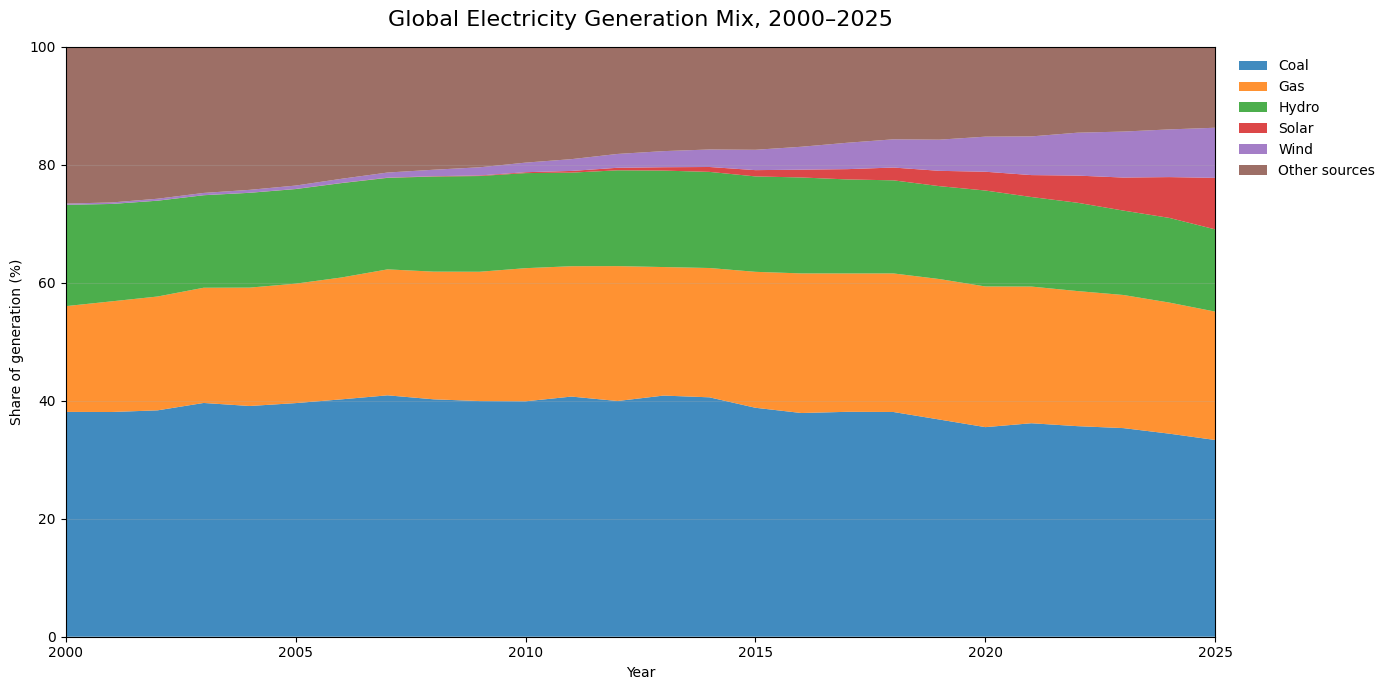

In [4]:
# ============================================================
# Figure 1 — Global Electricity Transition
#
# RQ1: Cơ cấu nguồn điện toàn cầu đã thay đổi như thế nào?
#
# Mục tiêu:
# - Thể hiện structural shift của electricity mix.
# - Tập trung vào 5 nguồn chính có trong global_sources: Coal, Gas, Hydro, Solar, Wind.
# - Phần còn lại được gom thành Other sources.
#
# Method:
# - Dùng Share of generation (%).
# - Không cộng component với aggregate.
# - Other = 100% - tổng 5 nguồn được theo dõi.
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Chuẩn bị dữ liệu
# ------------------------------------------------------------
main_sources = ["Coal", "Gas", "Hydro", "Solar", "Wind"]

global_mix = (
    global_sources[
        global_sources["Electricity source"].isin(main_sources)
    ]
    .pivot(
        index="Year",
        columns="Electricity source",
        values="Share of generation (%)"
    )
    .sort_index()
)

# ------------------------------------------------------------
# 2. Tạo phần Other sources
# ------------------------------------------------------------
global_mix["Other sources"] = (
    100 - global_mix[main_sources].sum(axis=1)
)

# ------------------------------------------------------------
# 3. Chỉ sử dụng giai đoạn 2000–2025
# ------------------------------------------------------------
global_mix = global_mix.loc[2000:2025]

plot_columns = [
    "Coal",
    "Gas",
    "Hydro",
    "Solar",
    "Wind",
    "Other sources"
]

plot_data = global_mix[plot_columns]

# ------------------------------------------------------------
# 4. Kiểm tra tổng cơ cấu
# ------------------------------------------------------------
total_share = plot_data.sum(axis=1)

print("=== FIGURE 1 — GLOBAL ELECTRICITY MIX ===")
print(
    f"Giai đoạn: {plot_data.index.min()} → {plot_data.index.max()}"
)
print(f"Số năm: {len(plot_data)}")

print("\nSai lệch lớn nhất so với 100%:")
print(f"{abs(total_share - 100).max():.10f} percentage points")

print("\n--- Cơ cấu năm 2000 ---")
display(
    plot_data.loc[2000]
    .to_frame("Share (%)")
    .round(3)
)

print("\n--- Cơ cấu năm 2025 ---")
display(
    plot_data.loc[2025]
    .to_frame("Share (%)")
    .round(3)
)

# ------------------------------------------------------------
# 5. Tính thay đổi 2000 → 2025
# ------------------------------------------------------------
change_2000_2025 = (
    plot_data.loc[2025] - plot_data.loc[2000]
)

print("\n--- Thay đổi 2000 → 2025 ---")

change_table = pd.DataFrame({
    "Share_2000_%": plot_data.loc[2000],
    "Share_2025_%": plot_data.loc[2025],
    "Change_pp": change_2000_2025
}).round(3)

display(change_table)

# ------------------------------------------------------------
# 6. Visualization
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 7))

ax.stackplot(
    plot_data.index,
    [plot_data[source] for source in plot_columns],
    labels=plot_columns,
    alpha=0.85
)

ax.set_title(
    "Global Electricity Generation Mix, 2000–2025",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Share of generation (%)")

ax.set_ylim(0, 100)
ax.set_xlim(2000, 2025)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# Figure 2 — Where Did the Transition Happen?
#
# RQ2: Sự chuyển dịch khỏi nguồn điện hóa thạch diễn ra mạnh
# ở những quốc gia nào?
#
# Mục tiêu:
# - Đưa kết quả Note 6 lên không gian địa lý.
# - Xác định các quốc gia có mức giảm Fossil share mạnh.
#
# Method:
# - Sử dụng Delta_Fossil_share_pp, giai đoạn 2012–2022.
# - Giá trị âm = Fossil share giảm.
# ============================================================

import plotly.express as px

# ------------------------------------------------------------
# 1. Chuẩn bị dữ liệu
# ------------------------------------------------------------
map_data = profile[
    [
        "Area",
        "Delta_Fossil_share_pp",
        "Delta_Renewables_share_pp",
        "Transition_direction",
        "Transition_intensity_pp"
    ]
].copy()

# Lấy ISO-3 từ dataframe gốc.
# Profile chỉ có Area nên merge với mapping Area → ISO 3 code.
area_iso = (
    df[
        ["Area", "ISO 3 code"]
    ]
    .dropna(subset=["ISO 3 code"])
    .drop_duplicates("Area")
)

map_data = map_data.merge(
    area_iso,
    on="Area",
    how="left"
)

# ------------------------------------------------------------
# 2. Kiểm tra coverage bản đồ
# ------------------------------------------------------------
print("=== FIGURE 2 — TRANSITION MAP ===")
print("Số quốc gia trong profile:", len(map_data))
print(
    "Có ISO-3:",
    map_data["ISO 3 code"].notna().sum()
)
print(
    "Thiếu ISO-3:",
    map_data["ISO 3 code"].isna().sum()
)

print("\n--- Top 10 quốc gia giảm Fossil share mạnh nhất ---")

top_transition = (
    map_data
    .sort_values("Delta_Fossil_share_pp")
    [
        [
            "Area",
            "ISO 3 code",
            "Delta_Fossil_share_pp",
            "Delta_Renewables_share_pp",
            "Transition_intensity_pp"
        ]
    ]
    .head(10)
)

display(top_transition.round(3))

# ------------------------------------------------------------
# 3. Vẽ choropleth
# ------------------------------------------------------------
fig = px.choropleth(
    map_data.dropna(subset=["ISO 3 code"]),
    locations="ISO 3 code",
    color="Delta_Fossil_share_pp",
    hover_name="Area",
    hover_data={
        "ISO 3 code": True,
        "Delta_Fossil_share_pp": ":.2f",
        "Delta_Renewables_share_pp": ":.2f",
        "Transition_intensity_pp": ":.2f"
    },
    title=(
        "Change in Fossil Share of Electricity Generation, "
        "2012–2022"
    ),
    labels={
        "Delta_Fossil_share_pp":
            "Change in Fossil Share (pp)",
        "Delta_Renewables_share_pp":
            "Change in Renewables Share (pp)",
        "Transition_intensity_pp":
            "Transition Intensity (pp)"
    },
    color_continuous_midpoint=0,
    projection="natural earth"
)

fig.update_layout(
    height=650,
    margin=dict(l=0, r=0, t=70, b=0)
)

fig.show()

=== FIGURE 2 — TRANSITION MAP ===
Số quốc gia trong profile: 209
Có ISO-3: 209
Thiếu ISO-3: 0

--- Top 10 quốc gia giảm Fossil share mạnh nhất ---


,Area,ISO 3 code,Delta_Fossil_share_pp,Delta_Renewables_share_pp,Transition_intensity_pp
110,Luxembourg,LUX,-74.718,74.718,74.718
42,Cook Islands (the),COK,-50.000,50.000,50.000
109,Lithuania,LTU,-48.530,48.530,48.530
105,Lebanon,LBN,-39.463,39.463,39.463
50,Djibouti,DJI,-35.000,35.000,35.000
107,Liberia,LBR,-33.333,33.333,33.333
143,Palestine (State of),PSE,-33.333,33.333,33.333
49,Denmark,DNK,-32.315,32.315,32.315
55,El Salvador,SLV,-30.164,30.164,30.164
30,Cambodia,KHM,-28.383,28.383,28.383


In [6]:
# ============================================================
# Kiểm tra cột strong_check
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Lấy dữ liệu transition + carbon
# ------------------------------------------------------------
carbon_transition = note08["strong_check"].copy()

print("Strong-check columns:")
print(carbon_transition.columns.tolist())

# ------------------------------------------------------------
# 2. Kiểm tra object strong_check
# ------------------------------------------------------------
display(
    carbon_transition.head()
)

print("\nShape:", carbon_transition.shape)

Strong-check columns:
['Area', 'Year', 'Generation (TWh)', 'Generation YoY change (TWh)', 'Generation YoY change (%)', 'Emissions (MtCO2e)', 'Emissions YoY change (MtCO2e)', 'Emissions YoY change (%)', 'Emissions intensity (gCO2e/kWh)', 'Ember region', 'decoupling_type', 'Generation_increase_abs', 'Emissions_reduction_abs', 'high_generation_increase', 'high_emissions_reduction', 'Intensity_previous', 'Delta_Intensity', 'Intensity_decreased']


,Area,Year,Generation (TWh),Generation YoY change (TWh),Generation YoY change (%),Emissions (MtCO2e),Emissions YoY change (MtCO2e),Emissions YoY change (%),Emissions intensity (gCO2e/kWh),Ember region,decoupling_type,Generation_increase_abs,Emissions_reduction_abs,high_generation_increase,high_emissions_reduction,Intensity_previous,Delta_Intensity,Intensity_decreased
0,Argentina,1997,72.46,2.70,3.870,21.835,-1.957,-8.225,301.339,Latin America and Caribbean,Generation ↑ / Emissions ↓,2.70,1.957,True,True,341.055,-39.716,True
1,Argentina,2023,148.56,2.95,2.026,52.122,-5.059,-8.847,350.848,Latin America and Caribbean,Generation ↑ / Emissions ↓,2.95,5.059,True,True,392.700,-41.852,True
2,Australia,2011,256.28,5.31,2.116,192.061,-2.602,-1.337,749.419,Oceania,Generation ↑ / Emissions ↓,5.31,2.602,True,True,775.643,-26.224,True
3,Australia,2018,262.63,3.66,1.413,180.831,-5.169,-2.779,688.539,Oceania,Generation ↑ / Emissions ↓,3.66,5.169,True,True,718.230,-29.691,True
4,Australia,2019,265.90,3.27,1.245,178.221,-2.610,-1.443,670.256,Oceania,Generation ↑ / Emissions ↓,3.27,2.610,True,True,688.539,-18.283,True



Shape: (106, 18)


In [7]:
# ============================================================
# Chuẩn bị dữ liệu cho Figure 3
#
# RQ3: Energy transition có đi kèm với thay đổi carbon intensity ở cấp quốc gia hay không?
#
# Mục tiêu:
# - Tạo Delta_Carbon_Intensity = Intensity_2022 - Intensity_2012 cho toàn bộ 209 quốc gia.
# - Ghép với Delta_Renewables_share_pp từ Note 6.
#
# Method:
# - Chỉ lấy Electricity source = Total generation.
# - So sánh 2012 → 2022.
# - Không dùng strong_check vì đó chỉ là subset Generation ↑ / Emissions ↓.
# ============================================================

# ------------------------------------------------------------
# 1. Lấy carbon intensity của Total generation
# ------------------------------------------------------------
total_generation = df[
    (df["Area type"] == "Country or economy") &
    (df["Electricity source"] == "Total generation") &
    (df["Year"].isin([2012, 2022]))
].copy()

intensity_panel = (
    total_generation
    .pivot(
        index="Area",
        columns="Year",
        values="Emissions intensity (gCO2e/kWh)"
    )
    .rename(
        columns={
            2012: "Intensity_2012",
            2022: "Intensity_2022"
        }
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Tính thay đổi carbon intensity
# ------------------------------------------------------------
intensity_panel["Delta_Carbon_Intensity"] = (
    intensity_panel["Intensity_2022"]
    - intensity_panel["Intensity_2012"]
)

# ------------------------------------------------------------
# 3. Ghép với energy transition
# ------------------------------------------------------------
figure3_data = transition_features[
    [
        "Area",
        "Delta_Fossil_share_pp",
        "Delta_Renewables_share_pp",
        "Delta_Solar_share_pp",
        "Delta_Wind_share_pp",
        "Delta_Hydro_share_pp"
    ]
].merge(
    intensity_panel[
        [
            "Area",
            "Intensity_2012",
            "Intensity_2022",
            "Delta_Carbon_Intensity"
        ]
    ],
    on="Area",
    how="inner"
)

# ------------------------------------------------------------
# 4. Kiểm tra dữ liệu
# ------------------------------------------------------------
print("=== FIGURE 3 — DATA CHECK ===")

print("Số quốc gia:", len(figure3_data))

print("\nMissing:")
display(
    figure3_data[
        [
            "Delta_Renewables_share_pp",
            "Delta_Carbon_Intensity"
        ]
    ]
    .isna()
    .sum()
    .to_frame("Missing")
)

print("\n--- 5 quốc gia đầu tiên ---")
display(
    figure3_data[
        [
            "Area",
            "Delta_Renewables_share_pp",
            "Delta_Carbon_Intensity",
            "Intensity_2012",
            "Intensity_2022"
        ]
    ]
    .head()
    .round(3)
)

print("\n--- Vietnam ---")
display(
    figure3_data[
        figure3_data["Area"] == "Viet Nam"
    ][
        [
            "Area",
            "Delta_Renewables_share_pp",
            "Delta_Carbon_Intensity",
            "Intensity_2012",
            "Intensity_2022"
        ]
    ].round(3)
)

=== FIGURE 3 — DATA CHECK ===
Số quốc gia: 209

Missing:


,Missing
Delta_Renewables_share_pp,0
Delta_Carbon_Intensity,0



--- 5 quốc gia đầu tiên ---


,Area,Delta_Renewables_share_pp,Delta_Carbon_Intensity,Intensity_2012,Intensity_2022
0,Afghanistan,2.367,-25.663,145.455,119.792
1,Albania,0.000,0.518,23.729,24.247
2,Algeria,-0.140,0.807,632.822,633.629
3,American Samoa,5.556,-34.028,656.250,622.222
4,Angola,4.579,-35.213,207.772,172.559



--- Vietnam ---


,Area,Delta_Renewables_share_pp,Delta_Carbon_Intensity,Intensity_2012,Intensity_2022
203,Viet Nam,3.074,45.672,371.857,417.529


=== FIGURE 3 — TRANSITION → CARBON OUTCOME ===
Số quốc gia: 209

Pearson correlation:
r = -0.8865
p = 3.2705e-71

Spearman correlation:
rho = -0.9056
p = 5.0128e-79

=== DIRECTIONAL PATTERNS ===


,Renewables_increase,Intensity_decrease,Count
0,False,False,46
1,False,True,10
2,True,False,7
3,True,True,146



=== VIET NAM ===


,Area,Delta_Renewables_share_pp,Delta_Carbon_Intensity,Renewables_increase,Intensity_decrease
203,Viet Nam,3.074,45.672,True,False


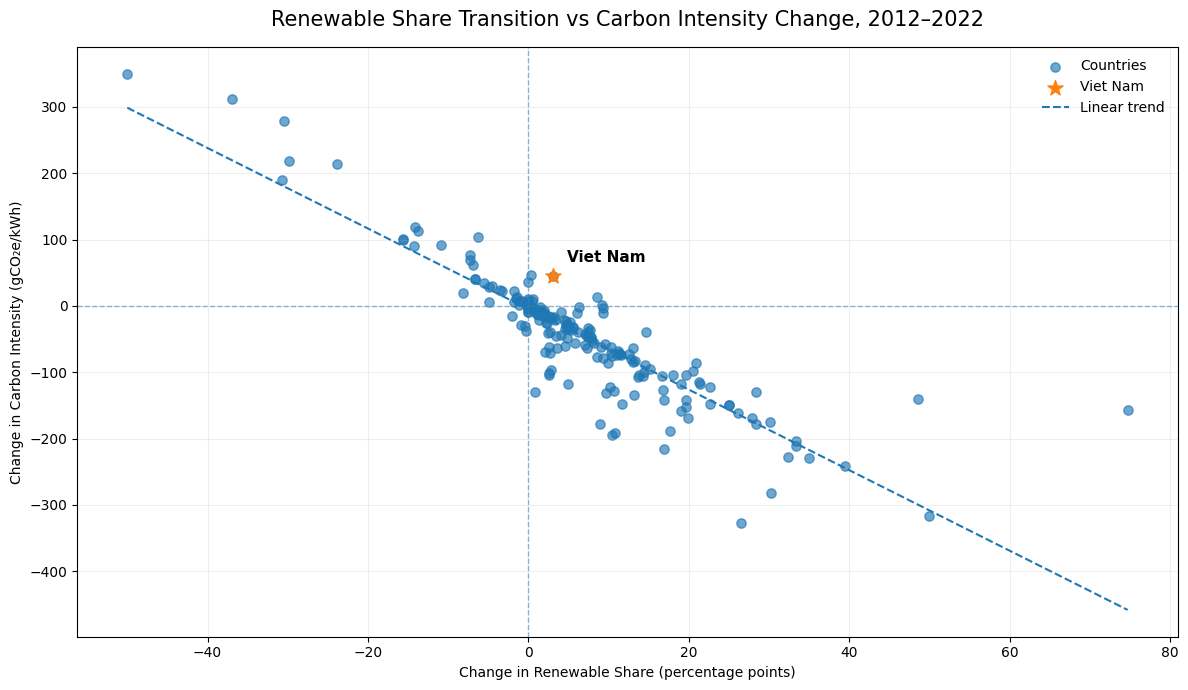

In [8]:
# ============================================================
# Figure 3 — Renewable Transition vs Carbon Intensity
#
# RQ3: Tăng tỷ trọng renewable có đi kèm cải thiện carbon intensity
# ở cấp quốc gia hay không?
#
# Mục tiêu:
# - Quan sát phân bố 209 quốc gia.
# - Xác định xu hướng chung giữa Renewable share change và Carbon intensity change.
# - Highlight Viet Nam như một trường hợp cần giải thích, không mặc định là trường hợp "tốt".
#
# Interpretation rule:
# - X > 0: Renewable share tăng.
# - Y < 0: Carbon intensity giảm.
# - Góc phần tư trên-trái: transition nhưng carbon intensity tăng.
# - Góc phần tư dưới-phải: transition đi kèm cải thiện carbon intensity.
#
# Lưu ý: Scatter chỉ cho thấy association, không chứng minh causality.
# ============================================================

from scipy.stats import pearsonr, spearmanr
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Dữ liệu hoàn chỉnh
# ------------------------------------------------------------
plot_df = figure3_data[
    [
        "Area",
        "Delta_Renewables_share_pp",
        "Delta_Carbon_Intensity"
    ]
].dropna().copy()

# ------------------------------------------------------------
# 2. Tính Pearson và Spearman để mô tả xu hướng
# ------------------------------------------------------------
pearson_r, pearson_p = pearsonr(
    plot_df["Delta_Renewables_share_pp"],
    plot_df["Delta_Carbon_Intensity"]
)

spearman_rho, spearman_p = spearmanr(
    plot_df["Delta_Renewables_share_pp"],
    plot_df["Delta_Carbon_Intensity"]
)

print("=== FIGURE 3 — TRANSITION → CARBON OUTCOME ===")
print("Số quốc gia:", len(plot_df))

print("\nPearson correlation:")
print(f"r = {pearson_r:.4f}")
print(f"p = {pearson_p:.4e}")

print("\nSpearman correlation:")
print(f"rho = {spearman_rho:.4f}")
print(f"p = {spearman_p:.4e}")

# ------------------------------------------------------------
# 3. Xác định các nhóm theo 2 chiều
# ------------------------------------------------------------
plot_df["Renewables_increase"] = (
    plot_df["Delta_Renewables_share_pp"] > 0
)

plot_df["Intensity_decrease"] = (
    plot_df["Delta_Carbon_Intensity"] < 0
)

print("\n=== DIRECTIONAL PATTERNS ===")

pattern = (
    plot_df
    .groupby(
        ["Renewables_increase", "Intensity_decrease"]
    )
    .size()
    .reset_index(name="Count")
)

display(pattern)

# ------------------------------------------------------------
# 4. Xác định Vietnam
# ------------------------------------------------------------
vietnam = plot_df[
    plot_df["Area"] == "Viet Nam"
].copy()

print("\n=== VIET NAM ===")
display(vietnam.round(3))

# ------------------------------------------------------------
# 5. Vẽ scatter plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

# Tất cả quốc gia
ax.scatter(
    plot_df["Delta_Renewables_share_pp"],
    plot_df["Delta_Carbon_Intensity"],
    alpha=0.65,
    s=45,
    label="Countries"
)

# Đường zero theo X
ax.axvline(
    0,
    linewidth=1,
    linestyle="--",
    alpha=0.5
)

# Đường zero theo Y
ax.axhline(
    0,
    linewidth=1,
    linestyle="--",
    alpha=0.5
)

# ------------------------------------------------------------
# 6. Highlight Vietnam
# ------------------------------------------------------------
if len(vietnam) == 1:

    x_vn = vietnam["Delta_Renewables_share_pp"].iloc[0]
    y_vn = vietnam["Delta_Carbon_Intensity"].iloc[0]

    ax.scatter(
        x_vn,
        y_vn,
        s=130,
        marker="*",
        label="Viet Nam"
    )

    ax.annotate(
        "Viet Nam",
        (x_vn, y_vn),
        xytext=(10, 10),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# 7. Regression line — chỉ mô tả xu hướng tổng thể
# ------------------------------------------------------------
x = plot_df["Delta_Renewables_share_pp"].values
y = plot_df["Delta_Carbon_Intensity"].values

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(
    x.min(),
    x.max(),
    200
)

y_line = slope * x_line + intercept

ax.plot(
    x_line,
    y_line,
    linestyle="--",
    linewidth=1.5,
    label="Linear trend"
)

# ------------------------------------------------------------
# 8. Labels và title
# ------------------------------------------------------------
ax.set_title(
    "Renewable Share Transition vs Carbon Intensity Change, 2012–2022",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Change in Renewable Share (percentage points)"
)

ax.set_ylabel(
    "Change in Carbon Intensity (gCO₂e/kWh)"
)

ax.grid(
    alpha=0.2
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

=== STRONG vs BAD — STATISTICAL COMPARISON ===


,Source,Strong_mean,Bad_mean,Mean_difference,Cohens_d,abs_Cohens_d
0,Fossil,-4.752,0.898,-5.651,-1.380,1.380
1,Renewables,4.473,-0.799,5.272,1.289,1.289
2,Hydro,3.625,-0.995,4.620,1.149,1.149
3,Wind,0.433,0.059,0.374,0.408,0.408
4,Nuclear,0.279,-0.099,0.378,0.361,0.361
5,Solar,0.392,0.146,0.245,0.240,0.240


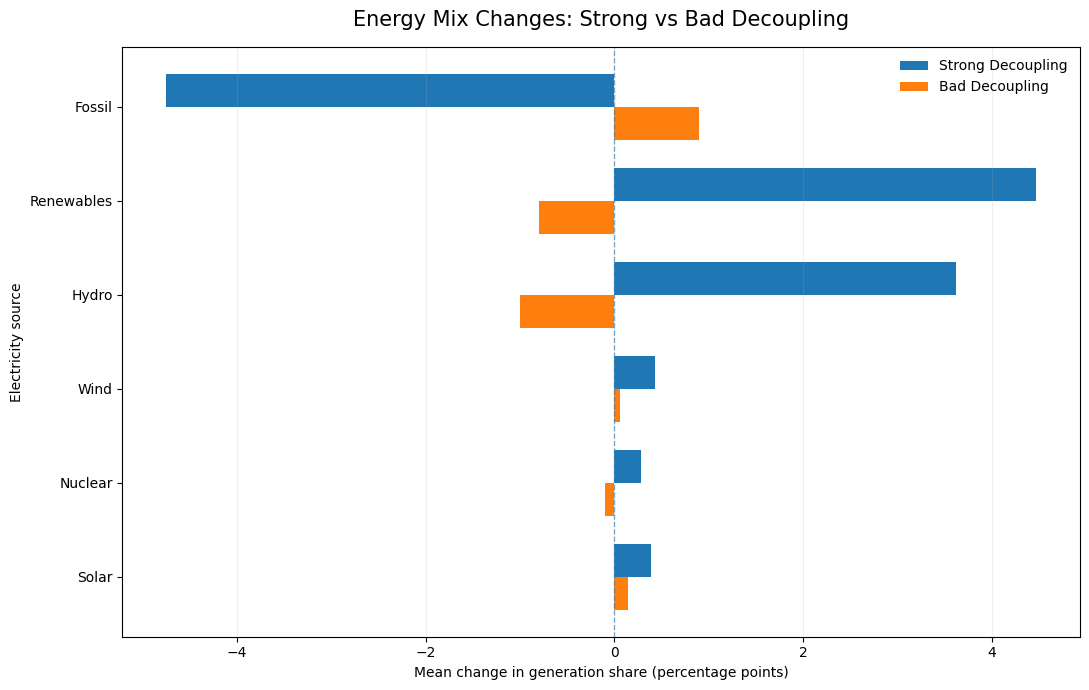


=== EFFECT SIZE RANKING ===


,Source,Mean_difference,Cohens_d,abs_Cohens_d
0,Fossil,-5.651,-1.380,1.380
1,Renewables,5.272,1.289,1.289
2,Hydro,4.620,1.149,1.149
3,Wind,0.374,0.408,0.408
4,Nuclear,0.378,0.361,0.361
5,Solar,0.245,0.240,0.240


In [9]:
# ============================================================
# Figure 4 — Strong vs Bad Decoupling
#
# RQ4: Khi sản lượng điện tăng, điều gì phân biệt trường hợp giảm phát thải với trường hợp phát thải tiếp tục tăng?
#
# Mục tiêu:
# - So sánh thay đổi cơ cấu nguồn điện giữa Strong và Bad.
# - Tập trung vào những nguồn có khác biệt rõ nhất.
#
# Method:
# - Sử dụng stat_results từ Note 8.
# - Mean_difference = Strong mean - Bad mean.
# - Cohen's d dùng để đánh giá magnitude của difference.
#
# Lưu ý: Đây là association/descriptive comparison, không phải bằng chứng nhân quả.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Kiểm tra kết quả thống kê
# ------------------------------------------------------------
comparison_plot = stat_results[
    [
        "Source",
        "Strong_mean",
        "Bad_mean",
        "Mean_difference",
        "Cohens_d",
        "abs_Cohens_d"
    ]
].copy()

print("=== STRONG vs BAD — STATISTICAL COMPARISON ===")
display(
    comparison_plot
    .sort_values("abs_Cohens_d", ascending=False)
    .round(3)
)

# ------------------------------------------------------------
# 2. Sắp xếp theo effect size
# ------------------------------------------------------------
comparison_plot = comparison_plot.sort_values(
    "abs_Cohens_d",
    ascending=True
)

sources = comparison_plot["Source"].tolist()

# ------------------------------------------------------------
# 3. Vẽ mean change comparison
# ------------------------------------------------------------
y = np.arange(len(sources))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    y + height / 2,
    comparison_plot["Strong_mean"],
    height=height,
    label="Strong Decoupling"
)

ax.barh(
    y - height / 2,
    comparison_plot["Bad_mean"],
    height=height,
    label="Bad Decoupling"
)

# Zero line
ax.axvline(
    0,
    linewidth=1,
    linestyle="--",
    alpha=0.6
)

ax.set_yticks(y)
ax.set_yticklabels(sources)

ax.set_xlabel(
    "Mean change in generation share (percentage points)"
)

ax.set_ylabel("Electricity source")

ax.set_title(
    "Energy Mix Changes: Strong vs Bad Decoupling",
    fontsize=15,
    pad=15
)

ax.grid(
    axis="x",
    alpha=0.2
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. In ranking effect size để diễn giải
# ------------------------------------------------------------
print("\n=== EFFECT SIZE RANKING ===")

display(
    stat_results[
        [
            "Source",
            "Mean_difference",
            "Cohens_d",
            "abs_Cohens_d"
        ]
    ]
    .sort_values(
        "abs_Cohens_d",
        ascending=False
    )
    .round(3)
)

Strong decoupling không chỉ là tăng điện nhưng giảm emissions; nó gắn với một thay đổi cơ cấu rất rõ: giảm tỷ trọng fossil và tăng renewable, trong đó hydro có đóng góp đáng kể ở cấp tổng thể.

=== FIGURE 5 — VIET NAM LONG-TERM TRANSITION ===
Số năm: 26
Giai đoạn: 2000 → 2025

=== SHARE CHECK ===
Maximum deviation from 100%: 0.001 percentage points
✓ Tất cả các năm đều có tổng share ≈ 100%.

=== VIET NAM MIX — 2000 ===


,Share (%)
Electricity source,
Coal,11.785
Gas,16.416
Hydro,54.782
Solar,0.000
Wind,0.000
Other,17.018



=== VIET NAM MIX — 2025 ===


,Share (%)
Electricity source,
Coal,48.314
Gas,6.208
Hydro,32.958
Solar,7.364
Wind,4.624
Other,0.532



=== CHANGE 2000 → 2025 ===


,Share_2000_%,Share_2025_%,Change_pp
Electricity source,,,
Coal,11.785,48.314,36.529
Solar,0.000,7.364,7.364
Wind,0.000,4.624,4.624
Gas,16.416,6.208,-10.208
Other,17.018,0.532,-16.486
Hydro,54.782,32.958,-21.824


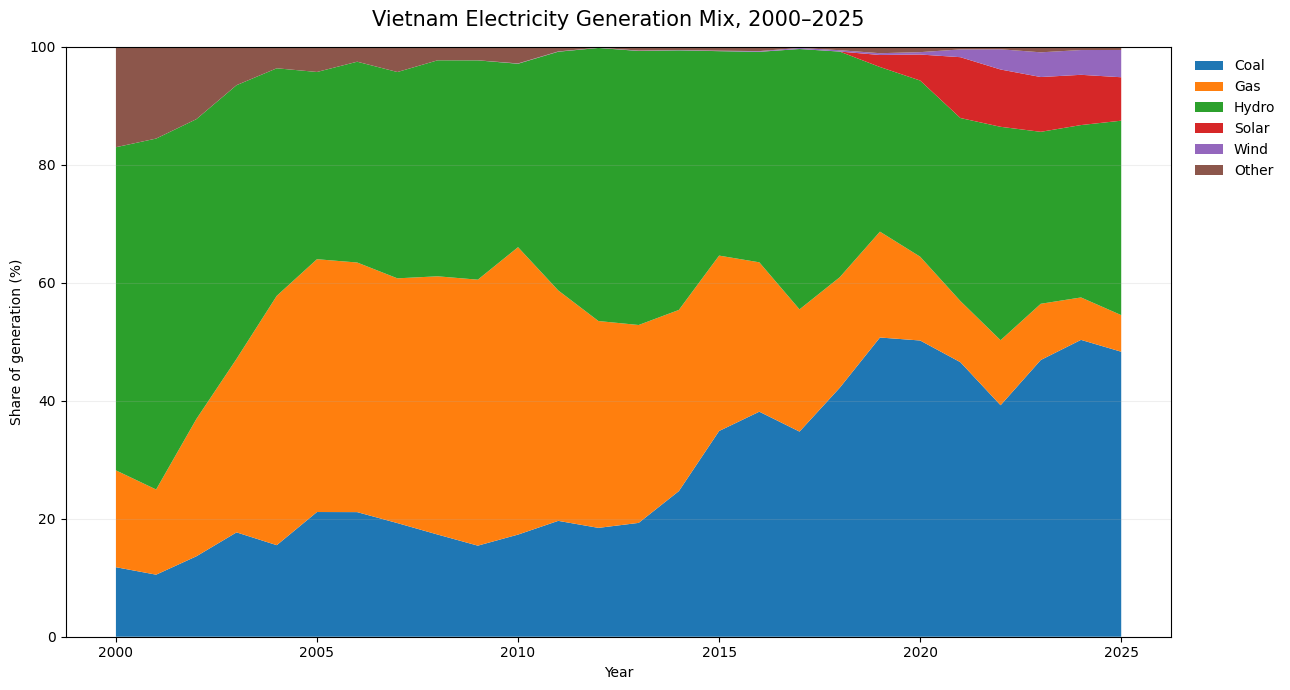

In [10]:
# ============================================================
# Figure 5 — Vietnam Long-term Electricity Transition
#
# RQ2 / Case Study: Vietnam đã thay đổi cơ cấu nguồn điện như thế nào trong giai đoạn 2000–2025?
#
# Mục tiêu:
# - Xây dựng cơ cấu nguồn điện hoàn chỉnh theo từng năm.
# - Không để missing source làm sai tổng share.
# - Làm nền cho Figure 6: turning point 2021–2022.
#
# Method:
# - Chỉ sử dụng các electricity sources thành phần.
# - Không cộng các dòng aggregate như Renewables/Fossil.
# - Missing source record được xử lý là 0 khi dựng cơ cấu, phù hợp với trường hợp nguồn chưa có phát điện được ghi nhận.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Các nguồn phát điện thành phần
# ------------------------------------------------------------
component_sources = [
    "Coal",
    "Gas",
    "Hydro",
    "Solar",
    "Wind",
    "Bioenergy",
    "Other renewables",
    "Nuclear",
    "Other fossil"
]

# ------------------------------------------------------------
# 2. Lọc Vietnam, Country or economy, 2000–2025
# ------------------------------------------------------------
vn_long = df[
    (df["Area"] == "Viet Nam") &
    (df["Area type"] == "Country or economy") &
    (df["Year"].between(2000, 2025)) &
    (df["Electricity source"].isin(component_sources))
].copy()

print("=== FIGURE 5 — VIET NAM LONG-TERM TRANSITION ===")
print(f"Số năm: {vn_long['Year'].nunique()}")
print(f"Giai đoạn: {vn_long['Year'].min()} → {vn_long['Year'].max()}")

# ------------------------------------------------------------
# 3. Pivot Share
# ------------------------------------------------------------
vn_mix = (
    vn_long
    .pivot_table(
        index="Year",
        columns="Electricity source",
        values="Share of generation (%)",
        aggfunc="first"
    )
    .sort_index()
)

# ------------------------------------------------------------
# 4. Đảm bảo tất cả source đều tồn tại
# ------------------------------------------------------------
vn_mix = vn_mix.reindex(
    index=range(2000, 2026),
    columns=component_sources
)

# ------------------------------------------------------------
# 5. Missing source record → 0
#
# Chỉ áp dụng khi dựng cơ cấu nguồn điện.
# Không dùng cách này để thay thế missing values
# trong các biến phân tích khác.
# ------------------------------------------------------------
vn_mix = vn_mix.fillna(0)

# ------------------------------------------------------------
# 6. Gom các nguồn nhỏ thành Other
# ------------------------------------------------------------
vn_mix["Other"] = (
    vn_mix["Bioenergy"]
    + vn_mix["Other renewables"]
    + vn_mix["Nuclear"]
    + vn_mix["Other fossil"]
)

vn_mix_plot = vn_mix[
    [
        "Coal",
        "Gas",
        "Hydro",
        "Solar",
        "Wind",
        "Other"
    ]
].copy()

# ------------------------------------------------------------
# 7. Kiểm tra tổng share
# ------------------------------------------------------------
share_sum = vn_mix_plot.sum(axis=1)

print("\n=== SHARE CHECK ===")
print(
    "Maximum deviation from 100%:",
    round(abs(share_sum - 100).max(), 6),
    "percentage points"
)

# ------------------------------------------------------------
# 8. Nếu vẫn lệch, in những năm có vấn đề
# ------------------------------------------------------------
problem_years = share_sum[
    abs(share_sum - 100) > 0.01
]

if len(problem_years) > 0:
    print("\n=== YEARS WITH SHARE DEVIATION > 0.01 pp ===")
    display(problem_years.to_frame("Total_share"))
else:
    print("✓ Tất cả các năm đều có tổng share ≈ 100%.")

# ------------------------------------------------------------
# 9. Cơ cấu đầu kỳ và cuối kỳ
# ------------------------------------------------------------
print("\n=== VIET NAM MIX — 2000 ===")
display(
    vn_mix_plot.loc[2000]
    .to_frame("Share (%)")
    .round(3)
)

print("\n=== VIET NAM MIX — 2025 ===")
display(
    vn_mix_plot.loc[2025]
    .to_frame("Share (%)")
    .round(3)
)

# ------------------------------------------------------------
# 10. Thay đổi 2000 → 2025
# ------------------------------------------------------------
vn_change = pd.DataFrame({
    "Share_2000_%": vn_mix_plot.loc[2000],
    "Share_2025_%": vn_mix_plot.loc[2025]
})

vn_change["Change_pp"] = (
    vn_change["Share_2025_%"]
    - vn_change["Share_2000_%"]
)

print("\n=== CHANGE 2000 → 2025 ===")
display(
    vn_change
    .sort_values("Change_pp", ascending=False)
    .round(3)
)

# ------------------------------------------------------------
# 11. Figure 5 — 100% stacked area
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 7))

ax.stackplot(
    vn_mix_plot.index,
    [
        vn_mix_plot[source]
        for source in vn_mix_plot.columns
    ],
    labels=vn_mix_plot.columns
)

ax.set_title(
    "Vietnam Electricity Generation Mix, 2000–2025",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Share of generation (%)")

ax.set_ylim(0, 100)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()
plt.show()

=== FIGURE 6 — VIET NAM TURNING POINT ===

=== SHARE CHECK ===


,Total_share
Year,
2020,100.0
2021,100.0
2022,100.0



=== SHARE OF GENERATION (%) ===


Year,2020,2021,2022
Electricity source,,,
Coal,50.217,46.540,39.244
Gas,14.205,10.374,11.022
Hydro,29.865,31.020,36.177
Solar,4.410,10.311,9.713
Wind,0.402,1.317,3.429
Other,0.901,0.438,0.415



=== 2020 → 2022 CHANGE ===


,Share_2020_%,Share_2022_%,Delta_share_pp,Generation_2020_TWh,Generation_2022_TWh,Delta_generation_TWh
Electricity source,,,,,,
Hydro,29.865,36.177,6.312,72.87,95.91,23.04
Solar,4.410,9.713,5.303,10.76,25.75,14.99
Wind,0.402,3.429,3.027,0.98,9.09,8.11
Other,0.901,0.415,-0.486,2.20,1.10,-1.10
Gas,14.205,11.022,-3.183,34.66,29.22,-5.44
Coal,50.217,39.244,-10.973,122.53,104.04,-18.49


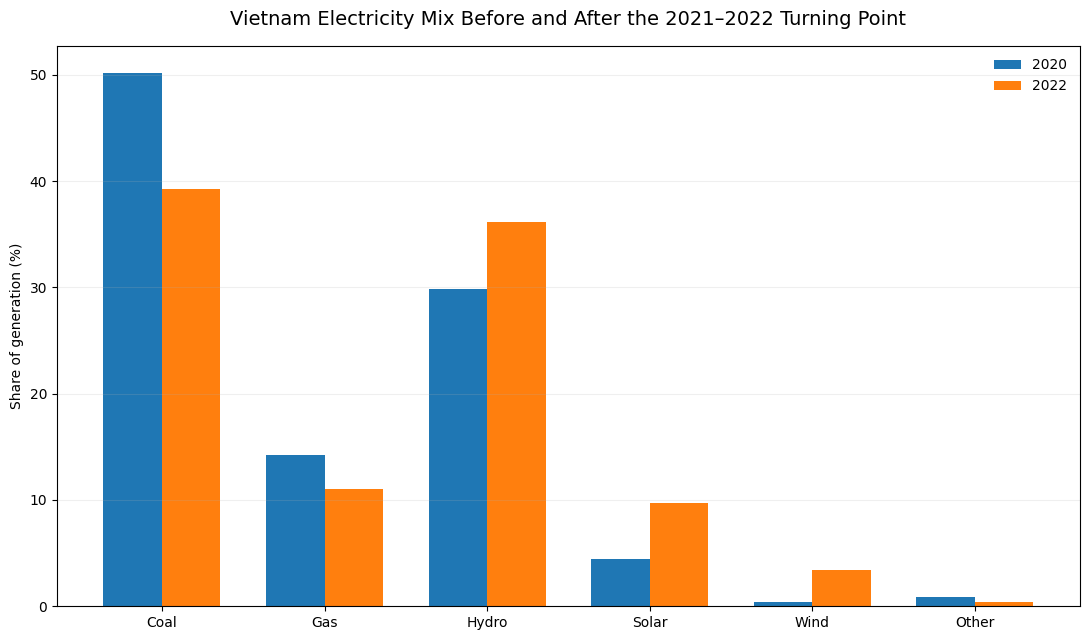

In [11]:
# ============================================================
# Figure 6 — Vietnam 2021–2022 Turning Point
#
# Vì sao 2021–2022 được xem là một turning point đáng chú ý trong quá trình chuyển dịch điện của Việt Nam?
#
# Mục tiêu:
# - So sánh cơ cấu nguồn điện trước và sau turning point.
# - Xác định nguồn nào tăng/giảm mạnh nhất.
# - Chuẩn bị bằng chứng cho "replacement pattern".
#
# Method:
# - So sánh 2020 → 2021 → 2022.
# - Sử dụng Share of generation (%) để nhìn cơ cấu.
# - Đồng thời tính Generation (TWh) để tránh nhầm giữa thay đổi tỷ trọng và thay đổi sản lượng tuyệt đối.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Lọc Vietnam và 3 năm 2020–2022
# ------------------------------------------------------------
vn_turn = df[
    (df["Area"] == "Viet Nam") &
    (df["Area type"] == "Country or economy") &
    (df["Year"].isin([2020, 2021, 2022])) &
    (df["Electricity source"].isin(component_sources))
].copy()

# ------------------------------------------------------------
# 2. Pivot generation và share
# ------------------------------------------------------------
vn_turn_share = (
    vn_turn
    .pivot_table(
        index="Year",
        columns="Electricity source",
        values="Share of generation (%)",
        aggfunc="first"
    )
    .reindex(index=[2020, 2021, 2022], columns=component_sources)
    .fillna(0)
)

vn_turn_generation = (
    vn_turn
    .pivot_table(
        index="Year",
        columns="Electricity source",
        values="Generation (TWh)",
        aggfunc="first"
    )
    .reindex(index=[2020, 2021, 2022], columns=component_sources)
    .fillna(0)
)

# ------------------------------------------------------------
# 3. Gom các nguồn nhỏ thành Other
# ------------------------------------------------------------
small_sources = [
    "Bioenergy",
    "Other renewables",
    "Nuclear",
    "Other fossil"
]

vn_turn_share["Other"] = vn_turn_share[small_sources].sum(axis=1)
vn_turn_generation["Other"] = vn_turn_generation[small_sources].sum(axis=1)

main_sources = [
    "Coal",
    "Gas",
    "Hydro",
    "Solar",
    "Wind",
    "Other"
]

vn_turn_share = vn_turn_share[main_sources]
vn_turn_generation = vn_turn_generation[main_sources]

# ------------------------------------------------------------
# 4. Kiểm tra tổng share
# ------------------------------------------------------------
print("=== FIGURE 6 — VIET NAM TURNING POINT ===")

share_check = vn_turn_share.sum(axis=1)

print("\n=== SHARE CHECK ===")
display(
    share_check
    .to_frame("Total_share")
    .round(3)
)

# ------------------------------------------------------------
# 5. Cơ cấu 2020 → 2022
# ------------------------------------------------------------
print("\n=== SHARE OF GENERATION (%) ===")
display(
    vn_turn_share
    .T
    .round(3)
)

# ------------------------------------------------------------
# 6. Thay đổi 2020 → 2022
# ------------------------------------------------------------
change_share = (
    vn_turn_share.loc[2022]
    - vn_turn_share.loc[2020]
)

change_generation = (
    vn_turn_generation.loc[2022]
    - vn_turn_generation.loc[2020]
)

turning_point = pd.DataFrame({
    "Share_2020_%": vn_turn_share.loc[2020],
    "Share_2022_%": vn_turn_share.loc[2022],
    "Delta_share_pp": change_share,
    "Generation_2020_TWh": vn_turn_generation.loc[2020],
    "Generation_2022_TWh": vn_turn_generation.loc[2022],
    "Delta_generation_TWh": change_generation
})

print("\n=== 2020 → 2022 CHANGE ===")
display(
    turning_point
    .sort_values("Delta_share_pp", ascending=False)
    .round(3)
)

# ------------------------------------------------------------
# 7. Vẽ thay đổi tỷ trọng nguồn điện
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6.5))

x = np.arange(len(main_sources))
width = 0.36

ax.bar(
    x - width / 2,
    vn_turn_share.loc[2020, main_sources],
    width,
    label="2020"
)

ax.bar(
    x + width / 2,
    vn_turn_share.loc[2022, main_sources],
    width,
    label="2022"
)

ax.set_xticks(x)
ax.set_xticklabels(main_sources)

ax.set_ylabel("Share of generation (%)")

ax.set_title(
    "Vietnam Electricity Mix Before and After the 2021–2022 Turning Point",
    fontsize=14,
    pad=15
)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

=== FIGURE 7 — VIET NAM SOURCE REPLACEMENT ===
Giai đoạn: 2020 → 2022

--- SOURCE CHANGE ---
Electricity source Share_2020_pct Share_2022_pct Delta_share_pp
              Coal         50.217         39.244        -10.973
               Gas         14.205         11.022         -3.183
      Other fossil          0.762          0.272         -0.490
           Nuclear          0.000          0.000         +0.000
         Bioenergy          0.139          0.143         +0.004
              Wind          0.402          3.429         +3.027
             Solar          4.410          9.713         +5.303
             Hydro         29.865         36.177         +6.312

--- NGUỒN TĂNG TỶ TRỌNG ---
Electricity source Delta_share_pp
             Hydro         +6.312
             Solar         +5.303
              Wind         +3.027
         Bioenergy         +0.004

--- NGUỒN GIẢM TỶ TRỌNG ---
Electricity source Delta_share_pp
              Coal        -10.973
               Gas         -3.183
 

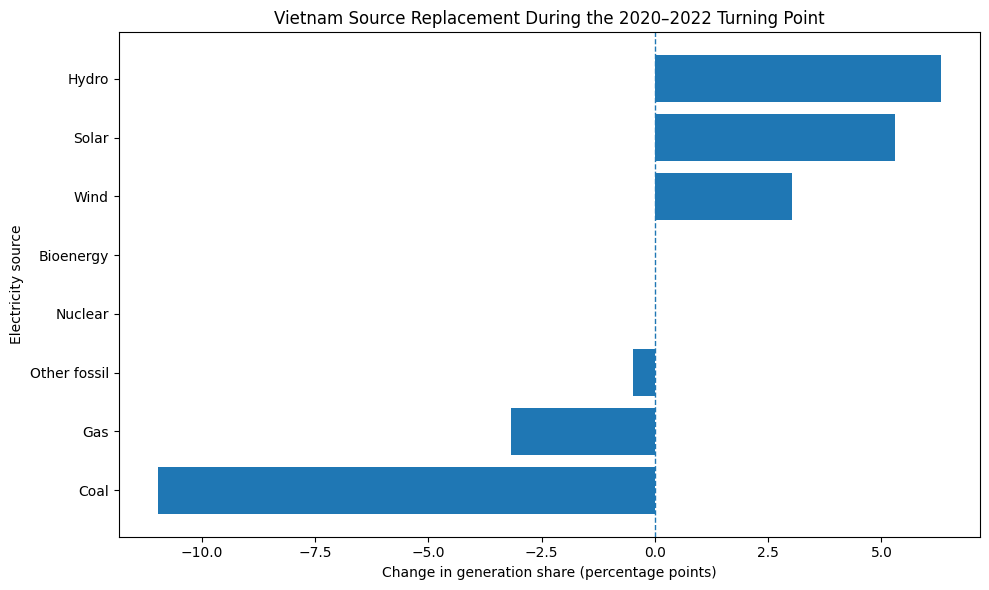

In [12]:
# ============================================================
# RQ4 / VIET NAM CASE
# - Nguồn nào tăng và nguồn nào giảm tỷ trọng trong turning point 2020 → 2022?
# - Xác định pattern "source replacement".
# ============================================================

# Các nguồn điện được sử dụng trong phân tích Việt Nam
vn_sources = [
    "Coal",
    "Gas",
    "Hydro",
    "Solar",
    "Wind",
    "Bioenergy",
    "Other renewables",
    "Other fossil",
    "Nuclear"
]

# Lọc dữ liệu Việt Nam trong 2020 và 2022
vn_replacement_raw = df[
    (df["Area"] == "Viet Nam") &
    (df["Area type"] == "Country or economy") &
    (df["Year"].isin([2020, 2022])) &
    (df["Electricity source"].isin(vn_sources))
].copy()

# Lấy share của từng nguồn
vn_replacement = (
    vn_replacement_raw
    .pivot_table(
        index="Electricity source",
        columns="Year",
        values="Share of generation (%)",
        aggfunc="first"
    )
    .reset_index()
)

# Đổi tên cho dễ đọc
vn_replacement = vn_replacement.rename(
    columns={
        2020: "Share_2020_pct",
        2022: "Share_2022_pct"
    }
)

# Tính thay đổi tỷ trọng
vn_replacement["Delta_share_pp"] = (
    vn_replacement["Share_2022_pct"]
    - vn_replacement["Share_2020_pct"]
)

# Loại nguồn không có đủ dữ liệu
vn_replacement = vn_replacement.dropna(
    subset=["Share_2020_pct", "Share_2022_pct"]
).copy()

# Sắp xếp từ giảm mạnh → tăng mạnh
vn_replacement = vn_replacement.sort_values(
    "Delta_share_pp"
).reset_index(drop=True)

print("=== FIGURE 7 — VIET NAM SOURCE REPLACEMENT ===")
print("Giai đoạn: 2020 → 2022")

print("\n--- SOURCE CHANGE ---")
print(
    vn_replacement[
        [
            "Electricity source",
            "Share_2020_pct",
            "Share_2022_pct",
            "Delta_share_pp"
        ]
    ].to_string(
        index=False,
        formatters={
            "Share_2020_pct": "{:.3f}".format,
            "Share_2022_pct": "{:.3f}".format,
            "Delta_share_pp": "{:+.3f}".format
        }
    )
)

print("\n--- NGUỒN TĂNG TỶ TRỌNG ---")
print(
    vn_replacement[
        vn_replacement["Delta_share_pp"] > 0
    ][
        ["Electricity source", "Delta_share_pp"]
    ]
    .sort_values("Delta_share_pp", ascending=False)
    .to_string(
        index=False,
        formatters={"Delta_share_pp": "{:+.3f}".format}
    )
)

print("\n--- NGUỒN GIẢM TỶ TRỌNG ---")
print(
    vn_replacement[
        vn_replacement["Delta_share_pp"] < 0
    ][
        ["Electricity source", "Delta_share_pp"]
    ]
    .sort_values("Delta_share_pp")
    .to_string(
        index=False,
        formatters={"Delta_share_pp": "{:+.3f}".format}
    )
)

# ============================================================
# Visualization
# Positive = tăng tỷ trọng
# Negative = giảm tỷ trọng
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    vn_replacement["Electricity source"],
    vn_replacement["Delta_share_pp"]
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Change in generation share (percentage points)")
plt.ylabel("Electricity source")
plt.title(
    "Vietnam Source Replacement During the 2020–2022 Turning Point"
)

plt.tight_layout()
plt.show()

=== FIGURE 8 — VIET NAM CARBON OUTCOME ===
Số năm: 26
Giai đoạn: 2000 → 2025

--- KEY YEARS ---
 Year Generation (TWh) Emissions (MtCO2e) Emissions intensity (gCO2e/kWh) Generation_index Emissions_index Intensity_index
 2000            26.56              8.548                         321.837            100.0           100.0           100.0
 2020           244.00            129.748                         531.754            918.7          1517.9           165.2
 2021           253.61            121.172                         477.789            954.9          1417.5           148.5
 2022           265.11            110.691                         417.529            998.2          1294.9           129.7
 2025           310.56            144.065                         463.892           1169.3          1685.4           144.1

--- TURNING POINT 2020 → 2022 ---
Generation: 244.000 → 265.110 | Δ = +21.110 | +8.65%
Emissions: 129.748 → 110.691 | Δ = -19.057 | -14.69%
Carbon intensity: 531.754

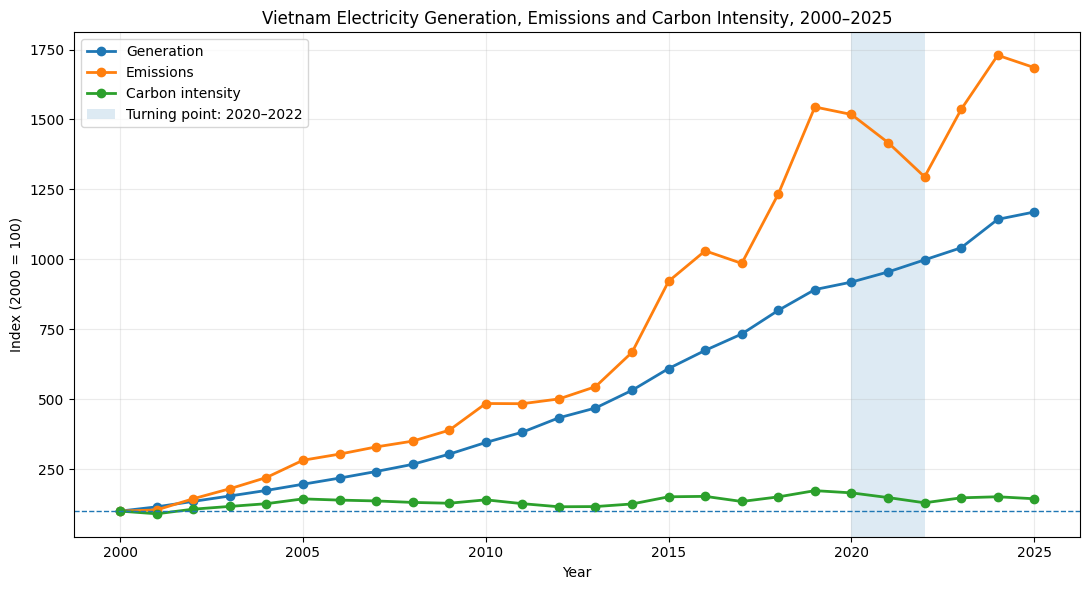

In [13]:
# ============================================================
# RQ3 / VIET NAM CASE
# - Sau quá trình chuyển dịch cơ cấu nguồn điện, carbon outcome của Việt Nam thay đổi như thế nào?
# - Nối source replacement với 3 system outcomes: Generation, Emissions và Carbon Intensity.
# ============================================================

# Lấy dữ liệu Total generation của Việt Nam
vn_carbon = df[
    (df["Area"] == "Viet Nam") &
    (df["Area type"] == "Country or economy") &
    (df["Electricity source"] == "Total generation") &
    (df["Year"].between(2000, 2025))
].copy()

vn_carbon = vn_carbon.sort_values("Year").reset_index(drop=True)

# Kiểm tra số năm
print("=== FIGURE 8 — VIET NAM CARBON OUTCOME ===")
print(f"Số năm: {len(vn_carbon)}")
print(f"Giai đoạn: {vn_carbon['Year'].min()} → {vn_carbon['Year'].max()}")

# ------------------------------------------------------------
# Tạo chỉ số 100 tại năm 2000 để so sánh xu hướng.
# Không dùng để thay thế giá trị thực tế.
# ------------------------------------------------------------

base_generation = vn_carbon["Generation (TWh)"].iloc[0]
base_emissions = vn_carbon["Emissions (MtCO2e)"].iloc[0]
base_intensity = vn_carbon["Emissions intensity (gCO2e/kWh)"].iloc[0]

vn_carbon["Generation_index"] = (
    vn_carbon["Generation (TWh)"] / base_generation * 100
)

vn_carbon["Emissions_index"] = (
    vn_carbon["Emissions (MtCO2e)"] / base_emissions * 100
)

vn_carbon["Intensity_index"] = (
    vn_carbon["Emissions intensity (gCO2e/kWh)"]
    / base_intensity * 100
)

# ------------------------------------------------------------
# In các mốc quan trọng
# ------------------------------------------------------------

key_years = vn_carbon[
    vn_carbon["Year"].isin([2000, 2020, 2021, 2022, 2025])
][
    [
        "Year",
        "Generation (TWh)",
        "Emissions (MtCO2e)",
        "Emissions intensity (gCO2e/kWh)",
        "Generation_index",
        "Emissions_index",
        "Intensity_index"
    ]
].copy()

print("\n--- KEY YEARS ---")
print(
    key_years.to_string(
        index=False,
        formatters={
            "Generation (TWh)": "{:.2f}".format,
            "Emissions (MtCO2e)": "{:.3f}".format,
            "Emissions intensity (gCO2e/kWh)": "{:.3f}".format,
            "Generation_index": "{:.1f}".format,
            "Emissions_index": "{:.1f}".format,
            "Intensity_index": "{:.1f}".format
        }
    )
)

# ------------------------------------------------------------
# Riêng turning point 2020 → 2022
# ------------------------------------------------------------

tp = vn_carbon[
    vn_carbon["Year"].isin([2020, 2022])
].set_index("Year")

print("\n--- TURNING POINT 2020 → 2022 ---")

for col, label in [
    ("Generation (TWh)", "Generation"),
    ("Emissions (MtCO2e)", "Emissions"),
    ("Emissions intensity (gCO2e/kWh)", "Carbon intensity")
]:
    start = tp.loc[2020, col]
    end = tp.loc[2022, col]
    change = end - start
    change_pct = change / start * 100

    print(
        f"{label}: "
        f"{start:.3f} → {end:.3f} | "
        f"Δ = {change:+.3f} | "
        f"{change_pct:+.2f}%"
    )

# ============================================================
# Visualization
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    vn_carbon["Year"],
    vn_carbon["Generation_index"],
    marker="o",
    linewidth=2,
    label="Generation"
)

plt.plot(
    vn_carbon["Year"],
    vn_carbon["Emissions_index"],
    marker="o",
    linewidth=2,
    label="Emissions"
)

plt.plot(
    vn_carbon["Year"],
    vn_carbon["Intensity_index"],
    marker="o",
    linewidth=2,
    label="Carbon intensity"
)

# Highlight turning-point period
plt.axvspan(
    2020,
    2022,
    alpha=0.15,
    label="Turning point: 2020–2022"
)

plt.axhline(
    100,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Year")
plt.ylabel("Index (2000 = 100)")
plt.title(
    "Vietnam Electricity Generation, Emissions and Carbon Intensity, 2000–2025"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

=== FIGURE 9 — VIET NAM vs GLOBAL PATHWAY ===
Giai đoạn: 2012 → 2022

                          Indicator  Vietnam  Global  Vietnam_minus_Global
           Fossil share change (pp)   -3.074  -6.601                 3.527
        Renewable share change (pp)    3.074   8.258                -5.184
Carbon intensity change (gCO2e/kWh)   45.672 -57.426               103.098

=== DIỄN GIẢI HƯỚNG THAY ĐỔI ===
Fossil share: Vietnam -3.074 pp | Global -6.601 pp
Renewable share: Vietnam +3.074 pp | Global +8.258 pp
Carbon intensity: Vietnam +45.672 gCO2e/kWh | Global -57.426 gCO2e/kWh
=== FIGURE 9 — VIET NAM vs GLOBAL PATHWAY ===
Giai đoạn: 2012 → 2022

                          Indicator  Vietnam  Global  Vietnam_minus_Global
           Fossil share change (pp)   -3.074  -6.601                 3.527
        Renewable share change (pp)    3.074   8.258                -5.184
Carbon intensity change (gCO2e/kWh)   45.672 -57.426               103.098


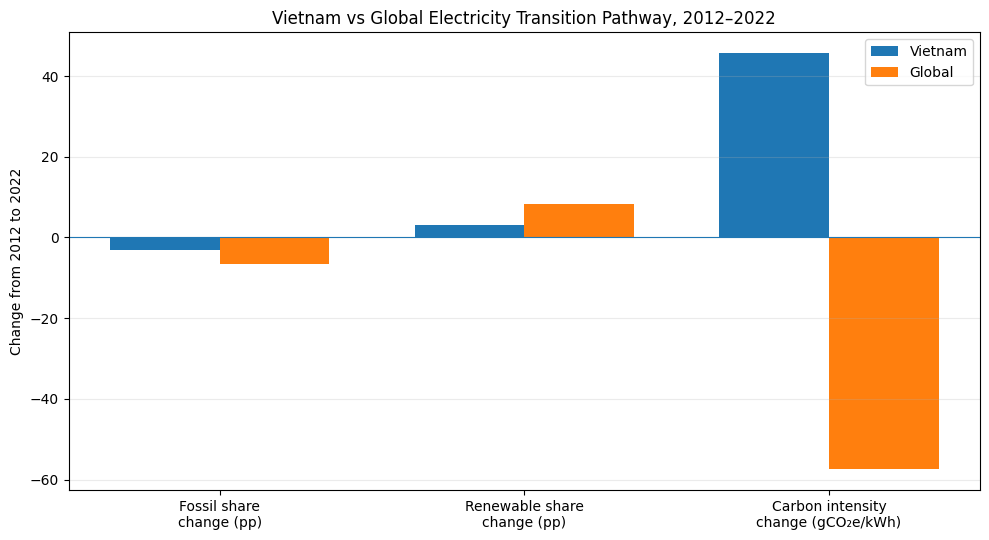


=== INTERPRETATION ===
Fossil share: Vietnam -3.074 pp | Global -6.601 pp
Renewable share: Vietnam +3.074 pp | Global +8.258 pp
Carbon intensity: Vietnam +45.672 gCO₂e/kWh | Global -57.426 gCO₂e/kWh


In [14]:
# ============================================================
# RQ4 / VIET NAM vs GLOBAL PATHWAY
# - Vietnam có đi cùng hướng với xu hướng chuyển dịch toàn cầu?
# - So sánh thay đổi 2012 → 2022 về:
#   1. Fossil share
#   2. Renewable share
#   3. Carbon intensity
#
# Mục đích: Xác định Vietnam nằm ở đâu trong bức tranh chuyển dịch
# năng lượng và carbon toàn cầu, trước khi tổng hợp kết luận.
# ============================================================

# ------------------------------------------------------------
# 1. LẤY DỮ LIỆU VIET NAM
# ------------------------------------------------------------

vn_total = df[
    (df["Area"] == "Viet Nam") &
    (df["Area type"] == "Country or economy") &
    (df["Year"].isin([2012, 2022])) &
    (df["Electricity source"].isin([
        "Fossil",
        "Renewables",
        "Total generation"
    ]))
].copy()

# Pivot để lấy giá trị 2012 và 2022
vn_pivot = vn_total.pivot_table(
    index="Electricity source",
    columns="Year",
    values=[
        "Share of generation (%)",
        "Emissions intensity (gCO2e/kWh)"
    ],
    aggfunc="first"
)

# ------------------------------------------------------------
# 2. TÍNH THAY ĐỔI CỦA VIETNAM
# ------------------------------------------------------------

vn_fossil_change = (
    vn_pivot.loc["Fossil", ("Share of generation (%)", 2022)]
    - vn_pivot.loc["Fossil", ("Share of generation (%)", 2012)]
)

vn_renewable_change = (
    vn_pivot.loc["Renewables", ("Share of generation (%)", 2022)]
    - vn_pivot.loc["Renewables", ("Share of generation (%)", 2012)]
)

vn_intensity_change = (
    vn_pivot.loc["Total generation", ("Emissions intensity (gCO2e/kWh)", 2022)]
    - vn_pivot.loc["Total generation", ("Emissions intensity (gCO2e/kWh)", 2012)]
)

# ------------------------------------------------------------
# 3. TÍNH THAY ĐỔI TOÀN CẦU
# ------------------------------------------------------------

global_total = df[
    (df["Area"] == "World") &
    (df["Year"].isin([2012, 2022])) &
    (df["Electricity source"].isin([
        "Fossil",
        "Renewables",
        "Total generation"
    ]))
].copy()

global_pivot = global_total.pivot_table(
    index="Electricity source",
    columns="Year",
    values=[
        "Share of generation (%)",
        "Emissions intensity (gCO2e/kWh)"
    ],
    aggfunc="first"
)

global_fossil_change = (
    global_pivot.loc["Fossil", ("Share of generation (%)", 2022)]
    - global_pivot.loc["Fossil", ("Share of generation (%)", 2012)]
)

global_renewable_change = (
    global_pivot.loc["Renewables", ("Share of generation (%)", 2022)]
    - global_pivot.loc["Renewables", ("Share of generation (%)", 2012)]
)

global_intensity_change = (
    global_pivot.loc["Total generation", ("Emissions intensity (gCO2e/kWh)", 2022)]
    - global_pivot.loc["Total generation", ("Emissions intensity (gCO2e/kWh)", 2012)]
)

# ------------------------------------------------------------
# 4. TẠO BẢNG SO SÁNH
# ------------------------------------------------------------

vn_global_comparison = pd.DataFrame({
    "Indicator": [
        "Fossil share change (pp)",
        "Renewable share change (pp)",
        "Carbon intensity change (gCO2e/kWh)"
    ],
    "Vietnam": [
        vn_fossil_change,
        vn_renewable_change,
        vn_intensity_change
    ],
    "Global": [
        global_fossil_change,
        global_renewable_change,
        global_intensity_change
    ]
})

vn_global_comparison["Vietnam_minus_Global"] = (
    vn_global_comparison["Vietnam"]
    - vn_global_comparison["Global"]
)

print("=== FIGURE 9 — VIET NAM vs GLOBAL PATHWAY ===")
print("Giai đoạn: 2012 → 2022")
print()

print(vn_global_comparison.round(3).to_string(index=False))

print()
print("=== DIỄN GIẢI HƯỚNG THAY ĐỔI ===")

print(
    f"Fossil share: Vietnam {vn_fossil_change:+.3f} pp | "
    f"Global {global_fossil_change:+.3f} pp"
)

print(
    f"Renewable share: Vietnam {vn_renewable_change:+.3f} pp | "
    f"Global {global_renewable_change:+.3f} pp"
)

print(
    f"Carbon intensity: Vietnam {vn_intensity_change:+.3f} gCO2e/kWh | "
    f"Global {global_intensity_change:+.3f} gCO2e/kWh"
)

# ============================================================
# FIGURE 9 — VIET NAM vs GLOBAL PATHWAY
#
# RQ → Vietnam có đi cùng pathway chuyển dịch toàn cầu không?
# Mục tiêu → trực quan hóa chênh lệch 2012 → 2022 giữa Vietnam
# và Global về Fossil, Renewables và Carbon intensity.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

print("=== FIGURE 9 — VIET NAM vs GLOBAL PATHWAY ===")
print("Giai đoạn: 2012 → 2022")
print()

print(vn_global_comparison.round(3).to_string(index=False))

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------
plot_df = vn_global_comparison.copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(plot_df))
width = 0.36

ax.bar(
    x - width / 2,
    plot_df["Vietnam"],
    width,
    label="Vietnam"
)

ax.bar(
    x + width / 2,
    plot_df["Global"],
    width,
    label="Global"
)

ax.axhline(0, linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Fossil share\nchange (pp)",
        "Renewable share\nchange (pp)",
        "Carbon intensity\nchange (gCO₂e/kWh)"
    ]
)

ax.set_ylabel("Change from 2012 to 2022")
ax.set_title(
    "Vietnam vs Global Electricity Transition Pathway, 2012–2022"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Interpretation support
# ------------------------------------------------------------
print("\n=== INTERPRETATION ===")

print(
    f"Fossil share: Vietnam {vn_fossil_change:+.3f} pp "
    f"| Global {global_fossil_change:+.3f} pp"
)

print(
    f"Renewable share: Vietnam {vn_renewable_change:+.3f} pp "
    f"| Global {global_renewable_change:+.3f} pp"
)

print(
    f"Carbon intensity: Vietnam {vn_intensity_change:+.3f} gCO₂e/kWh "
    f"| Global {global_intensity_change:+.3f} gCO₂e/kWh"
)

### Interpretation

Trong giai đoạn 2012–2022, Vietnam đi cùng hướng với xu thế toàn cầu ở hai khía cạnh: **Fossil share giảm** và **Renewable share tăng**.

Tuy nhiên, mức thay đổi của Vietnam nhỏ hơn Global đối với cả Fossil và Renewables. Đồng thời, Carbon intensity của Vietnam tăng trong khi Global giảm trong cùng giai đoạn.

Điều này cho thấy Vietnam **chưa đi hoàn toàn theo cùng pathway carbon với Global trong toàn bộ 2012–2022**.

Tuy nhiên, kết quả này không phủ nhận turning point ở giai đoạn cuối. Khi kết hợp với các Figure về Vietnam 2020–2022, có thể thấy Vietnam bắt đầu xuất hiện một pathway thuận lợi hơn: generation tăng trong khi emissions và carbon intensity giảm.

Do đó, Vietnam nên được diễn giải là **một transition pathway đang thay đổi**, thay vì một trường hợp đã hoàn toàn hội tụ với xu hướng toàn cầu.

## Final Synthesis

Các kết quả từ Note 01–08 được nối thành một evidence chain thống nhất.

Phân tích bắt đầu từ **Global Transition**, sau đó xác định **Structural Shifts**, chuyển sang **Country Transition Profiles**, kiểm tra mối liên hệ với **Carbon Outcome**, và cuối cùng kiểm tra trực tiếp các trường hợp **Decoupling**.

Vietnam được sử dụng như một case study để minh họa cách một quốc gia có thể chuyển từ một transition pathway chưa thuận lợi trong dài hạn sang một **turning point rõ rệt trong giai đoạn 2020–2022**.

### Evidence Chain

**Global Transition → Structural Shift → Country Pathway → Carbon Outcome → Decoupling → Strong vs Bad → International Spotlight → Vietnam Turning Point → Source Replacement → Vietnam vs Global → Conclusion**

In [15]:
# ============================================================
# FINAL SYNTHESIS — EVIDENCE CHAIN
#
# Sự chuyển dịch cơ cấu nguồn điện có đi kèm với quá trình giảm phát thải carbon hay không?
#
# Mục tiêu: Liên kết các kết quả từ Note 1 → Note 8 thành một chuỗi bằng chứng thống nhất.
# ============================================================

evidence_chain = pd.DataFrame([
    {
        "Stage": "1. Global transition",
        "Question": "Cơ cấu nguồn điện toàn cầu thay đổi thế nào?",
        "Key finding": "Renewables tăng từ 18.7% lên 33.5% trong 2000–2025; Fossil giảm từ 64.7% xuống 57.7%.",
        "Evidence": "Note 03"
    },
    {
        "Stage": "2. Structural shift",
        "Question": "Sự chuyển dịch diễn ra ở đâu và mức độ nào?",
        "Key finding": "Có sự khác biệt lớn giữa các quốc gia về mức giảm Fossil và tăng Renewables.",
        "Evidence": "Note 04–06"
    },
    {
        "Stage": "3. Transition → Carbon",
        "Question": "Chuyển dịch nguồn điện có liên hệ với carbon outcome không?",
        "Key finding": "Renewables ↔ Carbon intensity có tương quan âm rất mạnh (Spearman ρ = -0.906).",
        "Evidence": "Note 07–08"
    },
    {
        "Stage": "4. Decoupling",
        "Question": "Khi generation tăng, emissions có luôn tăng không?",
        "Key finding": "Có 669 trường hợp Generation tăng nhưng Emissions giảm; 3,096 trường hợp Generation và Emissions cùng tăng.",
        "Evidence": "Note 08"
    },
    {
        "Stage": "5. Strong vs Bad",
        "Question": "Điều gì phân biệt kết quả tốt và xấu?",
        "Key finding": "Strong Decoupling gắn với Fossil share giảm mạnh và Renewables share tăng; Fossil và Renewables có effect size lớn nhất.",
        "Evidence": "Note 08"
    },
    {
        "Stage": "6. Vietnam transition",
        "Question": "Vietnam chuyển dịch như thế nào?",
        "Key finding": "2000–2025: Coal tăng mạnh, Hydro giảm tỷ trọng; Solar và Wind xuất hiện và mở rộng đáng kể.",
        "Evidence": "Note 09 — Figure 5"
    },
    {
        "Stage": "7. Vietnam turning point",
        "Question": "Vietnam có turning point nào đáng chú ý?",
        "Key finding": "2020→2022: Generation +8.65%, Emissions -14.69%, Carbon intensity -21.48%.",
        "Evidence": "Note 09 — Figure 6 & 8"
    },
    {
        "Stage": "8. Vietnam replacement",
        "Question": "Nguồn nào thay đổi trong turning point?",
        "Key finding": "Coal -10.973 pp; Hydro +6.312 pp; Solar +5.303 pp; Wind +3.027 pp.",
        "Evidence": "Note 09 — Figure 7"
    },
    {
        "Stage": "9. Vietnam vs Global",
        "Question": "Vietnam có đi cùng pathway toàn cầu không?",
        "Key finding": "Vietnam giảm Fossil và tăng Renewables nhưng yếu hơn Global; Carbon intensity 2012–2022 tăng 45.672 gCO₂e/kWh trong khi Global giảm 57.426.",
        "Evidence": "Note 09 — Figure 9"
    }
])

print("=== FINAL EVIDENCE CHAIN ===")
display(evidence_chain)

print("\n=== CENTRAL STORY ===")
print("Transition → Structural Shift → Carbon Outcome → Decoupling →")
print("Strong vs Bad → Vietnam Turning Point → Source Replacement → Global Comparison")

=== FINAL EVIDENCE CHAIN ===


,Stage,Question,Key finding,Evidence
0,1. Global transition,Cơ cấu nguồn điện toàn cầu thay đổi thế nào?,Renewables tăng từ 18.7% lên 33.5% trong 2000–...,Note 03
1,2. Structural shift,Sự chuyển dịch diễn ra ở đâu và mức độ nào?,Có sự khác biệt lớn giữa các quốc gia về mức g...,Note 04–06
2,3. Transition → Carbon,Chuyển dịch nguồn điện có liên hệ với carbon o...,Renewables ↔ Carbon intensity có tương quan âm...,Note 07–08
3,4. Decoupling,"Khi generation tăng, emissions có luôn tăng kh...",Có 669 trường hợp Generation tăng nhưng Emissi...,Note 08
4,5. Strong vs Bad,Điều gì phân biệt kết quả tốt và xấu?,Strong Decoupling gắn với Fossil share giảm mạ...,Note 08
5,6. Vietnam transition,Vietnam chuyển dịch như thế nào?,"2000–2025: Coal tăng mạnh, Hydro giảm tỷ trọng...",Note 09 — Figure 5
6,7. Vietnam turning point,Vietnam có turning point nào đáng chú ý?,"2020→2022: Generation +8.65%, Emissions -14.69...",Note 09 — Figure 6 & 8
7,8. Vietnam replacement,Nguồn nào thay đổi trong turning point?,Coal -10.973 pp; Hydro +6.312 pp; Solar +5.303...,Note 09 — Figure 7
8,9. Vietnam vs Global,Vietnam có đi cùng pathway toàn cầu không?,Vietnam giảm Fossil và tăng Renewables nhưng y...,Note 09 — Figure 9



=== CENTRAL STORY ===
Transition → Structural Shift → Carbon Outcome → Decoupling →
Strong vs Bad → Vietnam Turning Point → Source Replacement → Global Comparison


=== FIGURE 10 — INTERNATIONAL SPOTLIGHT ===
Số case tìm thấy: 8


,Area,Year,Generation_change,Emissions_change,Spotlight
0,Japan,2011,-51.840,41.623,Japan — Generation ↓ / Emissions ↑
1,Japan,1993,9.310,-19.997,Japan — Generation ↑ / Emissions ↓
2,Japan,2004,28.600,-15.604,Japan — Generation ↑ / Emissions ↓
3,China,2015,17.551,-138.837,China — Strong Decoupling
4,China,2025,480.732,-53.681,China — Strong Decoupling
5,United States,2016,3.570,-86.289,US — Strong Decoupling
6,Viet Nam,2021,9.610,-8.576,Vietnam — Strong Decoupling
7,Viet Nam,2022,11.500,-10.481,Vietnam — Strong Decoupling


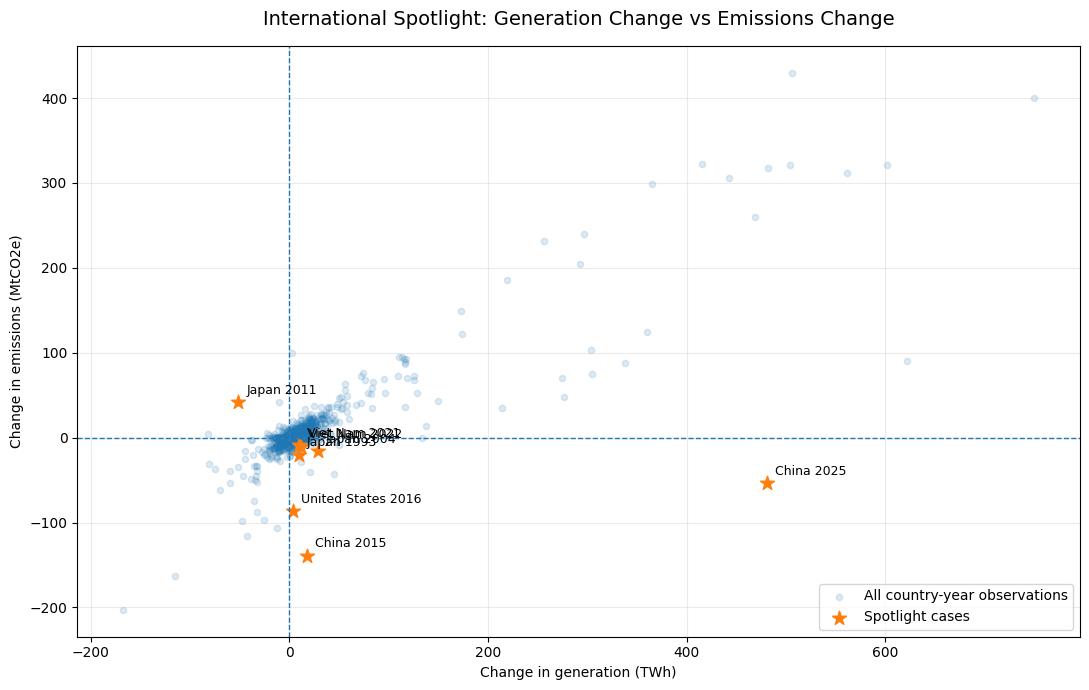

In [16]:
# ============================================================
# FIGURE 10 — INTERNATIONAL SPOTLIGHT CASES
# RQ4: Những country-year nào minh họa rõ các kiểu kết quả khác nhau của quá trình chuyển dịch điện → carbon?
#
# Mục tiêu:
# - Không chỉ spotlight Vietnam.
# - Đưa Japan, China, US và Vietnam vào cùng một khung.
# - Chọn các event đã xuất hiện trong phân tích của Note 8.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Lấy Total generation của toàn bộ country-year
# ------------------------------------------------------------

spotlight_base = df[
    (df["Area type"] == "Country or economy") &
    (df["Electricity source"] == "Total generation")
].copy()

spotlight_base = spotlight_base.sort_values(
    ["Area", "Year"]
).reset_index(drop=True)

# Tính thay đổi YoY nếu cần
spotlight_base["Generation_change"] = (
    spotlight_base
    .groupby("Area")["Generation (TWh)"]
    .diff()
)

spotlight_base["Emissions_change"] = (
    spotlight_base
    .groupby("Area")["Emissions (MtCO2e)"]
    .diff()
)

# ------------------------------------------------------------
# 2. Toàn bộ country-year dùng làm nền cho scatter
# ------------------------------------------------------------

plot_base = spotlight_base.dropna(
    subset=[
        "Generation_change",
        "Emissions_change"
    ]
).copy()

# ------------------------------------------------------------
# 3. Chọn các case spotlight
# ------------------------------------------------------------

case_conditions = [
    ("Japan", 2011, "Japan — Generation ↓ / Emissions ↑"),
    ("Japan", 1993, "Japan — Generation ↑ / Emissions ↓"),
    ("Japan", 2004, "Japan — Generation ↑ / Emissions ↓"),
    ("China", 2015, "China — Strong Decoupling"),
    ("China", 2025, "China — Strong Decoupling"),
    ("United States", 2016, "US — Strong Decoupling"),
    ("Viet Nam", 2021, "Vietnam — Strong Decoupling"),
    ("Viet Nam", 2022, "Vietnam — Strong Decoupling"),
]

spotlight_rows = []

for area, year, case_type in case_conditions:

    match = plot_base[
        (plot_base["Area"] == area) &
        (plot_base["Year"] == year)
    ]

    if len(match) == 0:
        print(f"⚠ Không tìm thấy: {area} — {year}")
        continue

    row = match.iloc[0]

    spotlight_rows.append({
        "Area": area,
        "Year": year,
        "Generation_change": row["Generation_change"],
        "Emissions_change": row["Emissions_change"],
        "Spotlight": case_type
    })

spotlight_df = pd.DataFrame(spotlight_rows)

# ------------------------------------------------------------
# 4. Kiểm tra các case trước khi vẽ
# ------------------------------------------------------------

print("=== FIGURE 10 — INTERNATIONAL SPOTLIGHT ===")
print(f"Số case tìm thấy: {len(spotlight_df)}")

display(
    spotlight_df[
        [
            "Area",
            "Year",
            "Generation_change",
            "Emissions_change",
            "Spotlight"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 5. Visualization
#
# Quadrants:
#   I   Generation ↑ / Emissions ↑
#   II  Generation ↓ / Emissions ↑
#   III Generation ↓ / Emissions ↓
#   IV  Generation ↑ / Emissions ↓
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

plt.scatter(
    plot_base["Generation_change"],
    plot_base["Emissions_change"],
    alpha=0.15,
    s=20,
    label="All country-year observations"
)

plt.scatter(
    spotlight_df["Generation_change"],
    spotlight_df["Emissions_change"],
    s=110,
    marker="*",
    label="Spotlight cases"
)

# Hai đường 0
plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

# Label spotlight
for _, row in spotlight_df.iterrows():

    label = f'{row["Area"]} {int(row["Year"])}'

    plt.annotate(
        label,
        (
            row["Generation_change"],
            row["Emissions_change"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Change in generation (TWh)")
plt.ylabel("Change in emissions (MtCO2e)")

plt.title(
    "International Spotlight: Generation Change vs Emissions Change",
    fontsize=14,
    pad=15
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# NOTE 09 — FINAL CHECKPOINT
# ============================================================

import pickle

checkpoint_path = project_root / "checkpoints" / "note09_final_synthesis.pkl"

note09_checkpoint = {
    # --------------------------------------------------------
    # International Spotlight
    # Figure 10: Các country-year dùng để minh họa những kiểu decoupling khác nhau.
    # --------------------------------------------------------
    "spotlight_df": spotlight_df,

    # --------------------------------------------------------
    # Final storyline
    # Chuỗi lập luận cuối cùng của toàn project.
    # --------------------------------------------------------
    "final_storyline": (
        "Global Transition → Structural Shift → Carbon Outcome → "
        "Decoupling → Strong vs Bad → International Spotlight → "
        "Vietnam Turning Point → Source Replacement → Conclusion"
    )
}

# ------------------------------------------------------------
# Lưu checkpoint
# ------------------------------------------------------------

with open(checkpoint_path, "wb") as f:
    pickle.dump(note09_checkpoint, f)

print("=== NOTE 09 FINAL CHECKPOINT ===")
print(f"Checkpoint: {checkpoint_path}")
print(f"Số object được lưu: {len(note09_checkpoint)}")
print()

for key, value in note09_checkpoint.items():
    if hasattr(value, "shape"):
        print(f"✓ {key}: {value.shape}")
    else:
        print(f"✓ {key}: {value}")

print()
print("Note 09 đã được checkpoint.")

=== NOTE 09 FINAL CHECKPOINT ===
Checkpoint: d:\phan tich data\Ember_Electricity\checkpoints\note09_final_synthesis.pkl
Số object được lưu: 2

✓ spotlight_df: (8, 5)
✓ final_storyline: Global Transition → Structural Shift → Carbon Outcome → Decoupling → Strong vs Bad → International Spotlight → Vietnam Turning Point → Source Replacement → Conclusion

Note 09 đã được checkpoint.


# Final Conclusion

## Research Question

**How does the transition in electricity generation mix relate to changes in carbon emissions across countries?**

## Main Findings

### 1. Global Transition

Trong giai đoạn 2000–2025, cơ cấu điện toàn cầu chuyển dịch theo hướng tăng vai trò của Renewables.

- Renewable share: **18.71% → 33.48%**
- Fossil share: **64.71% → 57.69%**
- Solar và Wind tăng mạnh về tỷ trọng.

Kết quả này thiết lập bối cảnh chung cho quá trình electricity transition.

### 2. Structural Shift

Mức độ chuyển dịch khác nhau đáng kể giữa các quốc gia. Một số quốc gia giảm mạnh Fossil share và tăng Renewables, trong khi một số quốc gia vẫn duy trì hoặc mở rộng Fossil generation.

Điều này cho thấy global transition không diễn ra theo một pathway duy nhất.

### 3. Transition → Carbon Outcome

Thay đổi trong electricity mix có mối liên hệ rõ với carbon intensity.

Đặc biệt, các quốc gia có mức tăng Renewable share lớn hơn thường đồng thời có xu hướng giảm Carbon intensity mạnh hơn.

Các kết quả này thể hiện **association**, không đủ để kết luận quan hệ nhân quả.

### 4. Decoupling

Trong các country-year observations hợp lệ, tồn tại những trường hợp **Generation tăng nhưng Emissions giảm**.

Điều này cho thấy tăng electricity generation không nhất thiết phải đi kèm với tăng emissions.

### 5. Strong vs Bad Decoupling

So sánh giữa hai nhóm cho thấy khác biệt nổi bật nhất nằm ở:

- **Fossil share**
- **Renewables share**
- **Hydro share**

Strong Decoupling có xu hướng giảm Fossil và tăng Renewables rõ rệt hơn Bad Decoupling.

### 6. Vietnam Turning Point

Vietnam có một turning point rõ trong giai đoạn **2020–2022**:

- Generation: **+8.65%**
- Emissions: **−14.69%**
- Carbon intensity: **−21.48%**

Trong cùng giai đoạn:

- Coal share: **−10.973 pp**
- Hydro share: **+6.312 pp**
- Solar share: **+5.303 pp**
- Wind share: **+3.027 pp**

Kết quả này cho thấy sự thay đổi cơ cấu nguồn điện đi cùng với một carbon outcome thuận lợi hơn trong giai đoạn turning point.

### 7. Vietnam vs Global

Trong giai đoạn 2012–2022, Vietnam đi cùng hướng với Global về giảm Fossil share và tăng Renewable share, nhưng mức chuyển dịch nhỏ hơn.

Đáng chú ý, Carbon intensity của Vietnam tăng trong khi Global giảm.

Vì vậy, Vietnam chưa thể được xem là đã hoàn toàn hội tụ với global pathway trong toàn bộ giai đoạn 2012–2022.

Tuy nhiên, giai đoạn 2020–2022 cho thấy một bước chuyển tích cực rõ rệt.

## Final Answer to the Research Question

**The evidence indicates that changes in electricity generation mix are consistently associated with differences in carbon outcomes across countries.**

Các trường hợp có carbon outcome thuận lợi hơn thường đi kèm với:

**Fossil share giảm + Renewables share tăng**

Trong đó, Hydro cũng đóng vai trò đáng kể ở một số transition pathways.

Tuy nhiên, phân tích này cho thấy **association rather than causation**. Carbon outcomes còn phụ thuộc vào quy mô hệ thống điện, technology mix và các đặc điểm riêng của từng quốc gia.

Vietnam là một case study đáng chú ý vì giai đoạn **2020–2022** cho thấy một turning point rõ: electricity generation tăng đồng thời với emissions và carbon intensity giảm.

## Final Storyline

**Global Transition → Structural Shift → Country Pathway → Carbon Outcome → Decoupling → Strong vs Bad → Vietnam Turning Point → Source Replacement → Vietnam vs Global → Conclusion**